In [187]:
import matplotlib.pyplot as plt
import nelpy as nel
import nelpy.plotting as npl
import numpy as np
import seaborn as sns
from neuro_py.io import loading
from neuro_py.plotting.figure_helpers import set_size
from neuro_py.tuning import maps
from skimage import measure
import os
import pandas as pd
import scipy.io as sio
import logging

logging.getLogger().setLevel(logging.ERROR)
basepath =  r"Z:\Data\AYAold\AYA10\day34"
basename=os.path.basename(basepath)# Define the new folder path
#create working folder
new_folder_path = os.path.join(basepath, "complex_system")
brain_region="CA1"
animal="mouse"   #or Mouse
cell_type='all'
path_parts = basepath.split("\\")  # Split the path using backslash
animal_name = path_parts[-2]  # Second-to-last part is the animal name
day = path_parts[-1]  # Last part is the day
save_dir = r"D:\Documents\GitHub\R_Project\PPP\codebook\Criticality_analysis\complex_system\manifold"
if not os.path.exists(save_dir):
    os.makedirs(save_dir)
# Create the folder if it doesn't exist
if not os.path.exists(new_folder_path):
    os.makedirs(new_folder_path)
    print(f"Folder created: {new_folder_path}")
else:
    print(f"Folder already exists: {new_folder_path}")
# load in spike data from hpc pyramidal cells

# load theta epochs
state_dict = loading.load_SleepState_states(basepath)
nrem_epochs = nel.EpochArray(
    state_dict["NREMstate"],
)
awake_epochs = nel.EpochArray(
    state_dict["WAKEstate"],
)
# theta_epochs = nel.EpochArray(
#     state_dict["THETA"],
# )
rem_epochs=nel.EpochArray(state_dict["REMstate"],)
try:
    # Try default loader
    epoch_df = loading.load_epoch(basepath)
except Exception as e:
    print(f"load_epoch failed with error: {e}")
    print("Falling back to manual .mat file load...")

    # Load the .mat file
    mat = sio.loadmat(os.path.join(basepath, "DayNight25.MergePoints.events.mat"), squeeze_me=True)

    # Extract the 'MergePoints' structure
    merge_points = mat['MergePoints']

    # Extract the timestamps array: shape (N, 2)
    timestamps = merge_points['timestamps']  # this is the field you're interested in
    # Unwrap the array inside
    timestamps = np.array(timestamps.tolist())

    # Now you should have shape (N, 2)
    epoch_df = pd.DataFrame(timestamps, columns=["startTime", "stopTime"])

sleep_epochs = nel.EpochArray(np.array([epoch_df.startTime, epoch_df.stopTime]).T)

# Load CA1 spikes
st_ca1, cm_ca1 = loading.load_spikes(basepath, brainRegion="CA1")
E_spikes_ca1 = st_ca1.time[(cm_ca1.putativeCellType == 'Pyramidal Cell')]
I_spikes_ca1 = st_ca1.time[(cm_ca1.putativeCellType.str.contains("Interneuron"))]
n_E_ca1 = len(E_spikes_ca1)
n_I_ca1 = len(I_spikes_ca1)
n_total_ca1 = len(st_ca1.time)
print(f"CA1 - Total cells: {n_total_ca1}, Excitatory: {n_E_ca1}, Interneurons: {n_I_ca1}")

# Load CA2 spikes
st_ca2, cm_ca2 = loading.load_spikes(basepath, brainRegion="CA2")
E_spikes_ca2 = st_ca2.time[(cm_ca2.putativeCellType == 'Pyramidal Cell')]
I_spikes_ca2 = st_ca2.time[(cm_ca2.putativeCellType.str.contains("Interneuron"))]
n_E_ca2 = len(E_spikes_ca2)
n_I_ca2 = len(I_spikes_ca2)
n_total_ca2 = len(st_ca2.time)
print(f"CA2 - Total cells: {n_total_ca2}, Excitatory: {n_E_ca2}, Interneurons: {n_I_ca2}")

# Load CA3 spikes
st_ca3, cm_ca3 = loading.load_spikes(basepath, brainRegion="CA3")
E_spikes_ca3 = st_ca3.time[(cm_ca3.putativeCellType == 'Pyramidal Cell')]
I_spikes_ca3 = st_ca3.time[(cm_ca3.putativeCellType.str.contains("Interneuron"))]
n_E_ca3 = len(E_spikes_ca3)
n_I_ca3 = len(I_spikes_ca3)
n_total_ca3 = len(st_ca3.time)
print(f"CA3 - Total cells: {n_total_ca3}, Excitatory: {n_E_ca3}, Interneurons: {n_I_ca3}")

Folder already exists: Z:\Data\AYAold\AYA10\day34\complex_system
CA1 - Total cells: 24, Excitatory: 21, Interneurons: 3
CA2 - Total cells: 20, Excitatory: 15, Interneurons: 5
CA3 - Total cells: 35, Excitatory: 33, Interneurons: 2


In [188]:
epoch_df

,name,startTime,stopTime,environment,behavioralParadigm,manipulation,stimuli,notes,basepath
0,pre,0.0,3995.1,sleep,7,NaN,NaN,NaN,Z:\Data\AYAold\AYA10\day34
1,task,3995.1,7946.2,cheeseboard,5,NaN,NaN,NaN,Z:\Data\AYAold\AYA10\day34
2,post,7946.2,13351.2,sleep,7,NaN,NaN,NaN,Z:\Data\AYAold\AYA10\day34


In [189]:
import os, re, numpy as np, pandas as pd
import glob  # <-- add this
def _load_mat_any(mat_path):
    from scipy.io import loadmat
    try:
        return loadmat(
            mat_path,
            squeeze_me=True,
            struct_as_record=False,
            simplify_cells=True
        )
    except TypeError:
        return loadmat(
            mat_path,
            squeeze_me=True,
            struct_as_record=False
        )
    except NotImplementedError:
        import mat73
        return mat73.loadmat(mat_path)
def _to_1d_array(x):
    """
    Robustly coerce MATLAB-loaded field to a 1D numpy array.
    - Scalars -> 1-length array
    - Lists/tuples/ndarrays -> flattened 1D
    - None / missing -> empty array
    """
    if x is None:
        return np.array([], dtype=float)
    arr = np.asarray(x, dtype=object)  # start as object to avoid surprises
    if arr.ndim == 0:
        # scalar or unsized object
        return np.atleast_1d(arr).astype(float, copy=False)
    # flatten and try float cast (ignore non-numeric gracefully)
    try:
        return np.asarray(arr).ravel().astype(float, copy=False)
    except (ValueError, TypeError):
        # fallback: best-effort, convert elementwise
        return np.array([float(v) for v in np.ravel(arr)], dtype=float)

def _to_state_str(s):
    # MATLAB char arrays sometimes come in as numpy arrays
    try:
        if isinstance(s, (bytes, bytearray)):
            return s.decode('utf-8', 'ignore')
        if isinstance(s, str):
            return s
        # arrays or weird containers -> join characters
        arr = np.asarray(s)
        if arr.ndim == 0:
            return str(arr.item())
        # e.g., array of characters
        return ''.join(arr.tolist()) if arr.dtype.kind in ('U','S') else str(arr)
    except Exception:
        return str(s)

def load_d2_timeline_complete(basepath, region):
    """Complete version that loads ALL sleep-state data, including d2_err."""
    region = region.upper()
    search_dir = os.path.join(basepath, "complex_system")
    # pats = [f"*_{region}_D2_time_resolved_rippleablate.mat", f"*_{region}_D2_time_rippleablate.mat"]
    pats = [f"*_{region}_D2_time_resolved_error_bar.mat", f"*_{region}_D2_time_error_bar.mat"]
    files = []
    for pat in pats:
        files.extend(glob.glob(os.path.join(search_dir, pat)))
    if not files:
        raise FileNotFoundError(f"No *_{region}_D2_time*.mat under {search_dir}")

    mat_path = max(files, key=os.path.getmtime)
    print(f"Loading: {os.path.basename(mat_path)}")

    mat = _load_mat_any(mat_path)
    results = mat['results']
    params = mat.get('params', {})

    # Make results iterable no matter if it's a list, ndarray, or dict
    if isinstance(results, dict):
        iter_results = list(results.values())
    else:
        iter_results = list(results if isinstance(results, (list, tuple)) else np.atleast_1d(results))

    print(f"📊 Found {len(iter_results)} result items (sleep states)")
    print(f"📊 Parameters: {params}")

    # Try to infer animal/day from filename if available
    fname = os.path.basename(mat_path)
    animal_name = None
    day = None
    m_day = re.search(r'day(\d+)', fname, flags=re.I)
    if m_day:
        day = int(m_day.group(1))
    m_animal = re.match(r'([^_]+)_day\d+_', fname)
    if m_animal:
        animal_name = m_animal.group(1)

    all_centers, all_d2, all_d2err, all_states = [], [], [], []
    n_states_with_err = 0

    for i, result_item in enumerate(iter_results):
        # Access as dict-like regardless of MATLAB struct quirks
        state = _to_state_str(result_item.get('state', 'UNKNOWN')) if hasattr(result_item, 'get') else \
                _to_state_str(result_item['state']) if (isinstance(result_item, dict) or hasattr(result_item, '__getitem__')) else 'UNKNOWN'

        centers_raw = result_item.get('center', []) if hasattr(result_item, 'get') else \
                      (result_item['center'] if (isinstance(result_item, dict) or hasattr(result_item, '__getitem__')) and 'center' in result_item else [])
        d2_raw = result_item.get('d2', []) if hasattr(result_item, 'get') else \
                 (result_item['d2'] if (isinstance(result_item, dict) or hasattr(result_item, '__getitem__')) and 'd2' in result_item else [])
        d2err_raw = result_item.get('d2_err', []) if hasattr(result_item, 'get') else \
                    (result_item['d2_err'] if (isinstance(result_item, dict) or hasattr(result_item, '__getitem__')) and 'd2_err' in result_item else [])

        centers  = _to_1d_array(centers_raw)
        d2_vals  = _to_1d_array(d2_raw)
        d2_err   = _to_1d_array(d2err_raw)

        # Presence flag (some states may not have d2_err)
        has_err = d2_err.size > 0 and np.any(np.isfinite(d2_err))
        n_states_with_err += int(has_err)

        # Harmonize lengths: truncate all to the common min
        sizes = [centers.size, d2_vals.size] + ([d2_err.size] if has_err else [])
        n_pts = min(sizes) if min(sizes) > 0 else 0
        print(f"   State {i}: {state} - requested points={centers.size}, actual used={n_pts}")

        if n_pts == 0:
            print("     ⚠️ Empty state - no data points")
            continue

        centers = centers[:n_pts]
        d2_vals = d2_vals[:n_pts]
        d2_err  = (d2_err[:n_pts] if has_err else np.full(n_pts, np.nan, dtype=float))

        # Ranges
        try:
            print(f"     Time range: {float(np.nanmin(centers))} to {float(np.nanmax(centers))}")
        except ValueError:
            print("     Time range: (all NaN)")

        try:
            print(f"     D2 range: {float(np.nanmin(d2_vals)):.4f} to {float(np.nanmax(d2_vals)):.4f}")
        except ValueError:
            print("     D2 range: (all NaN)")

        if np.any(np.isfinite(d2_err)):
            try:
                dmin, dmax = float(np.nanmin(d2_err)), float(np.nanmax(d2_err))
                print(f"     D2_ERR range: {dmin:.4f} to {dmax:.4f}")
            except ValueError:
                print("     D2_ERR range: (all NaN)")
        else:
            print("     D2_ERR: missing → filled with NaN")

        all_centers.append(centers)
        all_d2.append(d2_vals)
        all_d2err.append(d2_err)
        all_states.append(np.array([state]*n_pts, dtype=object))

    if len(all_centers) == 0:
        raise ValueError("No data found in any sleep state - all states are empty")

    # Concatenate
    all_centers = np.concatenate(all_centers)
    all_d2      = np.concatenate(all_d2)
    all_d2err   = np.concatenate(all_d2err)
    all_states  = np.concatenate(all_states)

    # DataFrame (include d2_err)
    df = pd.DataFrame({
        'center_s': all_centers.astype(float, copy=False),
        'd2':       all_d2.astype(float, copy=False),
        'd2_err':   all_d2err.astype(float, copy=False),
        'state':    all_states.astype(str)
    }).sort_values('center_s').reset_index(drop=True)

    print(f"\n✅ Complete timeline created:")
    print(f"📊 Total data points: {len(df)}")
    print(f"📊 Time range: {df['center_s'].min()} to {df['center_s'].max()}")
    print(f"📊 Duration: {(df['center_s'].max() - df['center_s'].min()):.1f} seconds")
    print(f"📊 State distribution:")
    print(df['state'].value_counts())

    # Empty-state tracker
    empty_states = []
    for ri in iter_results:
        st = _to_state_str(ri.get('state','UNKNOWN')) if hasattr(ri,'get') else \
             _to_state_str(ri['state']) if (isinstance(ri,dict) or hasattr(ri,'__getitem__')) and 'state' in ri else 'UNKNOWN'
        csz = np.size(np.atleast_1d(ri.get('center', []))) if hasattr(ri,'get') else \
              np.size(np.atleast_1d(ri['center'])) if (isinstance(ri,dict) or hasattr(ri,'__getitem__')) and 'center' in ri else 0
        if csz == 0:
            empty_states.append(st)

    meta = {
        "animal_name": animal_name,
        "day": day,
        "region": region,
        "path": mat_path,
        "params": params,
        "columns": list(df.columns),
        "shape": df.shape,
        "n_states": len(iter_results),
        "states_with_d2_err": n_states_with_err,
        "empty_states": empty_states
    }

    return df, meta



# Test the complete loading function
try:
    ca1_complete_df, ca1_complete_meta = load_d2_timeline_complete(basepath, "CA1")
    
    # pfc_complete_df, pfc_complete_meta = load_d2_timeline_complete(basepath, "PFC")

    
except Exception as e:
    print(f"❌ Failed: {e}")
    import traceback
    traceback.print_exc()

print("\n" + "="*60)

Loading: day34_CA1_D2_time_resolved_error_bar.mat
📊 Found 3 result items (sleep states)
📊 Parameters: {'window_size': 30, 'step_size': 2, 'guard_sec': 5, 'deltaT': 0.04, 'order': 20, 'quant': 0.1, 'brain_region': 'CA1', 'n_cells': 31, 'total_spikes': 238125}
   State 0: NREM - requested points=2241, actual used=2241
     Time range: 277.0 to 13315.0
     D2 range: 0.0452 to 0.2904
     D2_ERR range: 0.0168 to 0.0425
   State 1: REM - requested points=175, actual used=175
     Time range: 3218.0 to 13113.0
     D2 range: 0.0285 to 0.2000
     D2_ERR range: 0.0127 to 0.0342
   State 2: WAKE - requested points=3409, actual used=3409
     Time range: 21.0 to 14258.0
     D2 range: 0.0250 to 0.3182
     D2_ERR range: 0.0109 to 0.0447

✅ Complete timeline created:
📊 Total data points: 5825
📊 Time range: 21.0 to 14258.0
📊 Duration: 14237.0 seconds
📊 State distribution:
state
WAKE    3409
NREM    2241
REM      175
Name: count, dtype: int64



In [190]:
import numpy as np
from scipy.signal import welch
import nelpy as nel

def _flatten_spike_times(spike_times):
    """Accepts list/tuple/array of arrays or a single 1D array, returns sorted 1D float array."""
    if isinstance(spike_times, (list, tuple)):
        # list of arrays or scalars
        if len(spike_times) == 0:
            return np.array([], dtype=float)
        if hasattr(spike_times[0], "__len__") and not np.isscalar(spike_times[0]):
            valid_arrays = [np.asarray(st, dtype=float).ravel()
                           for st in spike_times if st is not None and len(st) > 0]
            if len(valid_arrays) == 0:
                return np.array([], dtype=float)
            times = np.concatenate(valid_arrays)
        else:
            times = np.asarray(spike_times, dtype=float).ravel()
    else:
        arr = np.asarray(spike_times, dtype=object)
        if arr.dtype == object:
            valid_arrays = [np.asarray(st, dtype=float).ravel()
                           for st in arr if st is not None and len(st) > 0]
            if len(valid_arrays) == 0:
                return np.array([], dtype=float)
            times = np.concatenate(valid_arrays)
        else:
            times = arr.astype(float).ravel()

    times = times[np.isfinite(times)]
    if times.size == 0:
        return np.array([], dtype=float)  # Return empty array instead of raising error
    return np.sort(times)

def bin_spikes(spike_times, bin_size=0.04, t_start=None, t_stop=None):
    st = _flatten_spike_times(spike_times)
    
    # Handle empty spike times
    if len(st) == 0:
        # Return empty arrays
        return np.array([]), np.array([])
    
    if t_start is None: t_start = float(np.floor(st.min()))
    if t_stop  is None: t_stop  = float(np.ceil(st.max()))
    edges = np.arange(t_start, t_stop + bin_size, bin_size)
    counts, _ = np.histogram(st, bins=edges)
    rates = counts / bin_size
    t = edges[:-1] + bin_size/2
    return t, rates

# def segments_from_epochs(t, x, epochs):
#     arr = epochs.data if isinstance(epochs, nel.EpochArray) else np.asarray(epochs)
#     return [x[(t >= s) & (t < e)] for s, e in arr if np.any((t >= s) & (t < e))]


In [191]:
# Create plot for random 200 second segment containing all states
import matplotlib.pyplot as plt
import numpy as np
import random

# First compute MUA from spike times
print("Computing MUA firing rate from spike times...")
print("="*50)

# Bin spikes for CA1 if not empty
if n_total_ca1 > 0:
    print("\nCA1 spike binning:")
    time_bins_ca1, firing_rate_ca1 = bin_spikes(st_ca1.time, bin_size=0.04)
    
    if n_E_ca1 > 0:
        time_bins_ca1_E, firing_rate_ca1_E = bin_spikes(E_spikes_ca1, bin_size=0.04)
        print(f"  CA1 Excitatory binned - rate range: {firing_rate_ca1_E.min():.2f} to {firing_rate_ca1_E.max():.2f} Hz")
    else:
        print("  CA1 Excitatory: No spikes")
        
    if n_I_ca1 > 0:
        time_bins_ca1_I, firing_rate_ca1_I = bin_spikes(I_spikes_ca1, bin_size=0.04)
        print(f"  CA1 Interneurons binned - rate range: {firing_rate_ca1_I.min():.2f} to {firing_rate_ca1_I.max():.2f} Hz")
    else:
        print("  CA1 Interneurons: No spikes")
else:
    print("\nCA1: No cells found")

# Bin spikes for CA2 if not empty
if n_total_ca2 > 0:
    print("\nCA2 spike binning:")
    time_bins_ca2, firing_rate_ca2 = bin_spikes(st_ca2.time, bin_size=0.04)
    
    if n_E_ca2 > 0:
        time_bins_ca2_E, firing_rate_ca2_E = bin_spikes(E_spikes_ca2, bin_size=0.04)
        print(f"  CA2 Excitatory binned - rate range: {firing_rate_ca2_E.min():.2f} to {firing_rate_ca2_E.max():.2f} Hz")
    else:
        print("  CA2 Excitatory: No spikes")
        
    if n_I_ca2 > 0:
        time_bins_ca2_I, firing_rate_ca2_I = bin_spikes(I_spikes_ca2, bin_size=0.04)
        print(f"  CA2 Interneurons binned - rate range: {firing_rate_ca2_I.min():.2f} to {firing_rate_ca2_I.max():.2f} Hz")
    else:
        print("  CA2 Interneurons: No spikes")
else:
    print("\nCA2: No cells found")

# Bin spikes for CA3 if not empty
if n_total_ca3 > 0:
    print("\nCA3 spike binning:")
    time_bins_ca3, firing_rate_ca3 = bin_spikes(st_ca3.time, bin_size=0.04)
    
    if n_E_ca3 > 0:
        time_bins_ca3_E, firing_rate_ca3_E = bin_spikes(E_spikes_ca3, bin_size=0.04)
        print(f"  CA3 Excitatory binned - rate range: {firing_rate_ca3_E.min():.2f} to {firing_rate_ca3_E.max():.2f} Hz")
    else:
        print("  CA3 Excitatory: No spikes")
        
    if n_I_ca3 > 0:
        time_bins_ca3_I, firing_rate_ca3_I = bin_spikes(I_spikes_ca3, bin_size=0.04)
        print(f"  CA3 Interneurons binned - rate range: {firing_rate_ca3_I.min():.2f} to {firing_rate_ca3_I.max():.2f} Hz")
    else:
        print("  CA3 Interneurons: No spikes")
else:
    print("\nCA3: No cells found")

Computing MUA firing rate from spike times...

CA1 spike binning:
  CA1 Excitatory binned - rate range: 0.00 to 425.00 Hz
  CA1 Interneurons binned - rate range: 0.00 to 100.00 Hz

CA2 spike binning:
  CA2 Excitatory binned - rate range: 0.00 to 300.00 Hz
  CA2 Interneurons binned - rate range: 0.00 to 400.00 Hz

CA3 spike binning:
  CA3 Excitatory binned - rate range: 0.00 to 375.00 Hz
  CA3 Interneurons binned - rate range: 0.00 to 350.00 Hz


In [192]:
import numpy as np
import pandas as pd

# --- Inputs assumed to exist ---
# time_bins_ca1, firing_rate_ca1, time_bins_ca1_E, firing_rate_ca1_E, time_bins_ca1_I, firing_rate_ca1_I
# time_bins_ca2, firing_rate_ca2, time_bins_ca2_E, firing_rate_ca2_E, time_bins_ca2_I, firing_rate_ca2_I
# time_bins_ca3, firing_rate_ca3, time_bins_ca3_E, firing_rate_ca3_E, time_bins_ca3_I, firing_rate_ca3_I
# ca1_complete_df          # has a 'center_s' column

def compute_mean_firing_rate_per_unit(time_bins, firing_rate, n_units, df, region_name, cell_type_name):
    """Compute mean firing rate per unit and add to dataframe"""
    if n_units == 0:
        print(f"{region_name} {cell_type_name}: No units - skipping")
        return

    # 1) Make sure we have bin centers
    tb = np.asarray(time_bins, float).ravel()
    fr = np.asarray(firing_rate, float).ravel()

    # Handle empty spike arrays (0 cells with spikes)
    if tb.size == 0 or fr.size == 0:
        print(f"{region_name} {cell_type_name}: No spike data - filling with NaN")
        col_name = f"{region_name}_{cell_type_name}_FR_per_unit"
        df[col_name] = np.nan
        return

    if tb.size == fr.size + 1:  # edges → make centers
        t = 0.5 * (tb[:-1] + tb[1:])
    elif tb.size == fr.size:  # already centers
        t = tb
    else:
        raise ValueError("time_bins length must equal firing_rate length or be exactly one longer (edges).")

    # 2) Clean + sort
    ok = np.isfinite(t) & np.isfinite(fr)
    t, fr = t[ok], fr[ok]

    # If no valid data after filtering, fill with NaN
    if len(t) == 0:
        print(f"{region_name} {cell_type_name}: No valid data after filtering - filling with NaN")
        col_name = f"{region_name}_{cell_type_name}_FR_per_unit"
        df[col_name] = np.nan
        return

    ordr = np.argsort(t)
    t, fr = t[ordr], fr[ordr]

    # 3) Compute mean firing rate per unit (Hz per unit)
    fr_per_unit = fr / n_units

    # 4) 30 s centered moving average
    # Handle case where we have too few points for meaningful window
    if len(t) < 2:
        # Not enough points to compute diff - use default bin size
        dt = 0.04
    else:
        dt = float(np.median(np.diff(t)))
        # Check for NaN (can happen if all diffs are NaN)
        if not np.isfinite(dt) or dt <= 0:
            dt = 0.04

    win_s = 30.0
    win_n = max(int(round(win_s / dt)), 1)

    fr_series = pd.Series(fr_per_unit, index=pd.Index(t, name="t"))
    fr_30s = fr_series.rolling(window=win_n, center=True, min_periods=max(1, win_n//4)).mean().to_numpy()

    # 5) Interpolate onto D² centers
    centers = np.asarray(df["center_s"], float)
    fr_at_centers = np.interp(centers, t, fr_30s, left=np.nan, right=np.nan)

    # 6) Save to dataframe (Hz per unit)
    col_name = f"{region_name}_{cell_type_name}_FR_per_unit"
    df[col_name] = fr_at_centers
    print(f"{region_name} {cell_type_name}: Added column '{col_name}' (mean: {np.nanmean(fr_at_centers):.3f} Hz/unit)")

# Process CA1
if n_total_ca1 > 0:
    print("\n" + "="*50)
    print("Processing CA1 mean firing rates per unit:")
    print("="*50)
    compute_mean_firing_rate_per_unit(time_bins_ca1, firing_rate_ca1, n_total_ca1, 
                                      ca1_complete_df, "CA1", "All")
    if n_E_ca1 > 0:
        compute_mean_firing_rate_per_unit(time_bins_ca1_E, firing_rate_ca1_E, n_E_ca1, 
                                          ca1_complete_df, "CA1", "E")
    if n_I_ca1 > 0:
        compute_mean_firing_rate_per_unit(time_bins_ca1_I, firing_rate_ca1_I, n_I_ca1, 
                                          ca1_complete_df, "CA1", "I")

# Process CA2
if n_total_ca2 > 0:
    print("\n" + "="*50)
    print("Processing CA2 mean firing rates per unit:")
    print("="*50)
    compute_mean_firing_rate_per_unit(time_bins_ca2, firing_rate_ca2, n_total_ca2, 
                                      ca1_complete_df, "CA2", "All")
    if n_E_ca2 > 0:
        compute_mean_firing_rate_per_unit(time_bins_ca2_E, firing_rate_ca2_E, n_E_ca2, 
                                          ca1_complete_df, "CA2", "E")
    if n_I_ca2 > 0:
        compute_mean_firing_rate_per_unit(time_bins_ca2_I, firing_rate_ca2_I, n_I_ca2, 
                                          ca1_complete_df, "CA2", "I")

# Process CA3
if n_total_ca3 > 0:
    print("\n" + "="*50)
    print("Processing CA3 mean firing rates per unit:")
    print("="*50)
    compute_mean_firing_rate_per_unit(time_bins_ca3, firing_rate_ca3, n_total_ca3, 
                                      ca1_complete_df, "CA3", "All")
    if n_E_ca3 > 0:
        compute_mean_firing_rate_per_unit(time_bins_ca3_E, firing_rate_ca3_E, n_E_ca3, 
                                          ca1_complete_df, "CA3", "E")
    if n_I_ca3 > 0:
        compute_mean_firing_rate_per_unit(time_bins_ca3_I, firing_rate_ca3_I, n_I_ca3, 
                                          ca1_complete_df, "CA3", "I")

print("\n" + "="*50)
print("Summary of added columns:")
print(ca1_complete_df.filter(regex='FR_per_unit').columns.tolist())
print("="*50)


Processing CA1 mean firing rates per unit:
CA1 All: Added column 'CA1_All_FR_per_unit' (mean: 0.705 Hz/unit)
CA1 E: Added column 'CA1_E_FR_per_unit' (mean: 0.674 Hz/unit)
CA1 I: Added column 'CA1_I_FR_per_unit' (mean: 0.916 Hz/unit)

Processing CA2 mean firing rates per unit:
CA2 All: Added column 'CA2_All_FR_per_unit' (mean: 2.426 Hz/unit)
CA2 E: Added column 'CA2_E_FR_per_unit' (mean: 1.015 Hz/unit)
CA2 I: Added column 'CA2_I_FR_per_unit' (mean: 6.657 Hz/unit)

Processing CA3 mean firing rates per unit:
CA3 All: Added column 'CA3_All_FR_per_unit' (mean: 2.185 Hz/unit)
CA3 E: Added column 'CA3_E_FR_per_unit' (mean: 0.613 Hz/unit)
CA3 I: Added column 'CA3_I_FR_per_unit' (mean: 28.115 Hz/unit)

Summary of added columns:
['CA1_All_FR_per_unit', 'CA1_E_FR_per_unit', 'CA1_I_FR_per_unit', 'CA2_All_FR_per_unit', 'CA2_E_FR_per_unit', 'CA2_I_FR_per_unit', 'CA3_All_FR_per_unit', 'CA3_E_FR_per_unit', 'CA3_I_FR_per_unit']


In [193]:
ca1_complete_df

,center_s,d2,d2_err,state,CA1_All_FR_per_unit,CA1_E_FR_per_unit,CA1_I_FR_per_unit,CA2_All_FR_per_unit,CA2_E_FR_per_unit,CA2_I_FR_per_unit,CA3_All_FR_per_unit,CA3_E_FR_per_unit,CA3_I_FR_per_unit
0,21.0,0.155848,0.024664,WAKE,0.681250,0.691270,0.611111,2.484167,1.001111,6.933333,2.365238,0.474242,33.566667
1,23.0,0.156365,0.024900,WAKE,0.726389,0.746825,0.583333,2.466667,0.993333,6.886667,2.345714,0.458081,33.491667
2,25.0,0.165246,0.025377,WAKE,0.754861,0.780952,0.572222,2.442500,0.985556,6.813333,2.380476,0.445455,34.308333
3,27.0,0.173128,0.025701,WAKE,0.731944,0.757143,0.555556,2.445833,0.981111,6.840000,2.357143,0.439899,33.991667
4,29.0,0.175487,0.025609,WAKE,0.743056,0.766667,0.577778,2.420000,0.950000,6.830000,2.311905,0.438384,33.225000
...,...,...,...,...,...,...,...,...,...,...,...,...,...
5820,14250.0,0.046584,0.015189,WAKE,1.422222,1.434921,1.333333,3.118333,1.562222,7.786667,2.915714,0.855556,36.908333
5821,14252.0,0.045699,0.015333,WAKE,1.479861,1.498413,1.350000,3.160000,1.526667,8.060000,3.003810,0.846970,38.591667
5822,14254.0,0.048547,0.016021,WAKE,1.537500,1.557143,1.400000,3.136667,1.491111,8.073333,3.035238,0.798990,39.933333
5823,14256.0,0.052439,0.016593,WAKE,1.553472,1.575397,1.400000,3.121667,1.474444,8.063333,3.109524,0.776768,41.600000


SWR and barrage

In [194]:
import numpy as np
import scipy.io as sio      
import scipy
# Load ripple events
ripple_events = loading.load_ripples_events(basepath=basepath)
ripple_epochs = nel.EpochArray(np.array([ripple_events.start, ripple_events.stop]).T)
ripple_peaks=ripple_events.peaks
# Load barrage events
ripple_epochs=nrem_epochs&ripple_epochs
try:
    # Load barrage events
    #brpath=r"W:\data\PPP\CA2\PPP7\day8"
    # barrage_events = loading.load_barrage_events(basepath=basepath)  
    # # Create barrage epochs
    # barrage_epochs = nel.EpochArray(np.array([barrage_events.start, barrage_events.stop]).T)
    # # Find barrages in NREM epochs
    # barrages_in_nrem = barrage_epochs & nrem_epochs
    mat_path = os.path.join(basepath, r"BARR_archive", f'{basename}.HSEn2.events.mat')
    #mat_path = os.path.join(basepath, f'{basename}.HSEn2.events.mat')

    data = scipy.io.loadmat(mat_path, struct_as_record=False, squeeze_me=True)
    barrage = data['HSEn2']
    barrage_timestamps = barrage.timestamps 
    
    # Create barrage epochs from timestamps
    if barrage_timestamps.ndim == 1:
        # Single barrage or timestamps need to be reshaped
        barrage_timestamps = barrage_timestamps.reshape(-1, 2)
    barrage_epochs = nel.EpochArray(barrage_timestamps)
    barrage_epochs = nrem_epochs & barrage_epochs
    
    # Compute barrage rate for each center_s with 30s window
    print("\n" + "="*50)
    print("Computing barrage rate with 30s window:")
    print("="*50)
    
    centers = ca1_complete_df["center_s"].values
    barrage_rate = np.zeros(len(centers))
    window_size = 30.0  # seconds
    
    # Extract barrage epoch data
    if hasattr(barrage_epochs, 'data') and len(barrage_epochs.data) > 0:
        barrage_data = barrage_epochs.data  # shape (n_barrages, 2) with [start, stop]
        
        for i, center in enumerate(centers):
            # Define window around center
            win_start = center - window_size / 2
            win_stop = center + window_size / 2
            
            # Count barrages that overlap with this window
            # A barrage overlaps if: barrage_start < win_stop AND barrage_stop > win_start
            overlaps = (barrage_data[:, 0] < win_stop) & (barrage_data[:, 1] > win_start)
            n_barrages = np.sum(overlaps)
            
            # Convert to rate (events per second)
            barrage_rate[i] = n_barrages / window_size
        
        ca1_complete_df["barrage_rate"] = barrage_rate
        print(f"Added 'barrage_rate' column (mean: {np.mean(barrage_rate):.4f} Hz)")
        print(f"Barrage rate range: {np.min(barrage_rate):.4f} to {np.max(barrage_rate):.4f} Hz")
        print(f"Total barrages detected: {len(barrage_data)}")
    else:
        print("No barrage epochs found - setting barrage_rate to 0")
        ca1_complete_df["barrage_rate"] = 0.0
        
except Exception as e:
    # General exception for unexpected errors
    print(f"No barrage file: {e}")
    barrage_epochs = []
    ca1_complete_df["barrage_rate"] = 0.0
    print("Set barrage_rate to 0.0")

# Compute ripple rate for each center_s with 30s window
print("" + "="*50)
print("Computing ripple rate with 30s window:")
print("="*50)

centers = ca1_complete_df["center_s"].values
ripple_rate = np.zeros(len(centers))
window_size = 30.0  # seconds

# Extract ripple epoch data
if hasattr(ripple_epochs, 'data') and len(ripple_epochs.data) > 0:
    ripple_data = ripple_epochs.data  # shape (n_ripples, 2) with [start, stop]
    
    for i, center in enumerate(centers):
        # Define window around center
        win_start = center - window_size / 2
        win_stop = center + window_size / 2
        
        # Count ripples that overlap with this window
        # A ripple overlaps if: ripple_start < win_stop AND ripple_stop > win_start
        overlaps = (ripple_data[:, 0] < win_stop) & (ripple_data[:, 1] > win_start)
        n_ripples = np.sum(overlaps)
        
        # Convert to rate (events per second)
        ripple_rate[i] = n_ripples / window_size
    
    ca1_complete_df["ripple_rate"] = ripple_rate
    print(f"Added 'ripple_rate' column (mean: {np.mean(ripple_rate):.4f} Hz)")
    print(f"Ripple rate range: {np.min(ripple_rate):.4f} to {np.max(ripple_rate):.4f} Hz")
    print(f"Total ripples detected: {len(ripple_data)}")
else:
    print("No ripple epochs found - setting ripple_rate to 0")
    ca1_complete_df["ripple_rate"] = 0.0


# Compute ripple rate for each center_s with 30s window
print("" + "="*50)
print("Computing ripple rate with 30s window:")
print("="*50)

centers = ca1_complete_df["center_s"].values
ripple_rate = np.zeros(len(centers))
window_size = 30.0  # seconds

# Extract ripple epoch data
if hasattr(ripple_epochs, 'data') and len(ripple_epochs.data) > 0:
    ripple_data = ripple_epochs.data  # shape (n_ripples, 2) with [start, stop]
    
    for i, center in enumerate(centers):
        # Define window around center
        win_start = center - window_size / 2
        win_stop = center + window_size / 2
        
        # Count ripples that overlap with this window
        # A ripple overlaps if: ripple_start < win_stop AND ripple_stop > win_start
        overlaps = (ripple_data[:, 0] < win_stop) & (ripple_data[:, 1] > win_start)
        n_ripples = np.sum(overlaps)
        
        # Convert to rate (events per second)
        ripple_rate[i] = n_ripples / window_size
    
    ca1_complete_df["ripple_rate"] = ripple_rate
    print(f"Added 'ripple_rate' column (mean: {np.mean(ripple_rate):.4f} Hz)")
    print(f"Ripple rate range: {np.min(ripple_rate):.4f} to {np.max(ripple_rate):.4f} Hz")
    print(f"Total ripples detected: {len(ripple_data)}")
else:
    print("No ripple epochs found - setting ripple_rate to 0")
    ca1_complete_df["ripple_rate"] = 0.0



Computing barrage rate with 30s window:
Added 'barrage_rate' column (mean: 0.0033 Hz)
Barrage rate range: 0.0000 to 0.1333 Hz
Total barrages detected: 56
Computing ripple rate with 30s window:
Added 'ripple_rate' column (mean: 0.2103 Hz)
Ripple rate range: 0.0000 to 1.1667 Hz
Total ripples detected: 3004
Computing ripple rate with 30s window:
Added 'ripple_rate' column (mean: 0.2103 Hz)
Ripple rate range: 0.0000 to 1.1667 Hz
Total ripples detected: 3004


Plotting 395 points with non-zero barrage rate

FORCED SEXTILE (Percentile-based binning):

CA1 Excitatory:
  Percentile edges: [0.03333333 0.03333333 0.03333333 0.03333333 0.06666667 0.06666667
 0.13333333]
  Tile counts: [242, 153]

CA1 Interneurons:
  Percentile edges: [0.03333333 0.03333333 0.03333333 0.03333333 0.06666667 0.06666667
 0.13333333]
  Tile counts: [242, 153]

CA1 All Cells:
  Percentile edges: [0.03333333 0.03333333 0.03333333 0.03333333 0.06666667 0.06666667
 0.13333333]
  Tile counts: [242, 153]

CA2 Excitatory:
  Percentile edges: [0.03333333 0.03333333 0.03333333 0.03333333 0.06666667 0.06666667
 0.13333333]
  Tile counts: [242, 153]

CA2 Interneurons:
  Percentile edges: [0.03333333 0.03333333 0.03333333 0.03333333 0.06666667 0.06666667
 0.13333333]
  Tile counts: [242, 153]

CA2 All Cells:
  Percentile edges: [0.03333333 0.03333333 0.03333333 0.03333333 0.06666667 0.06666667
 0.13333333]
  Tile counts: [242, 153]

CA3 Excitatory:
  Percentile edges: [0.03333333 

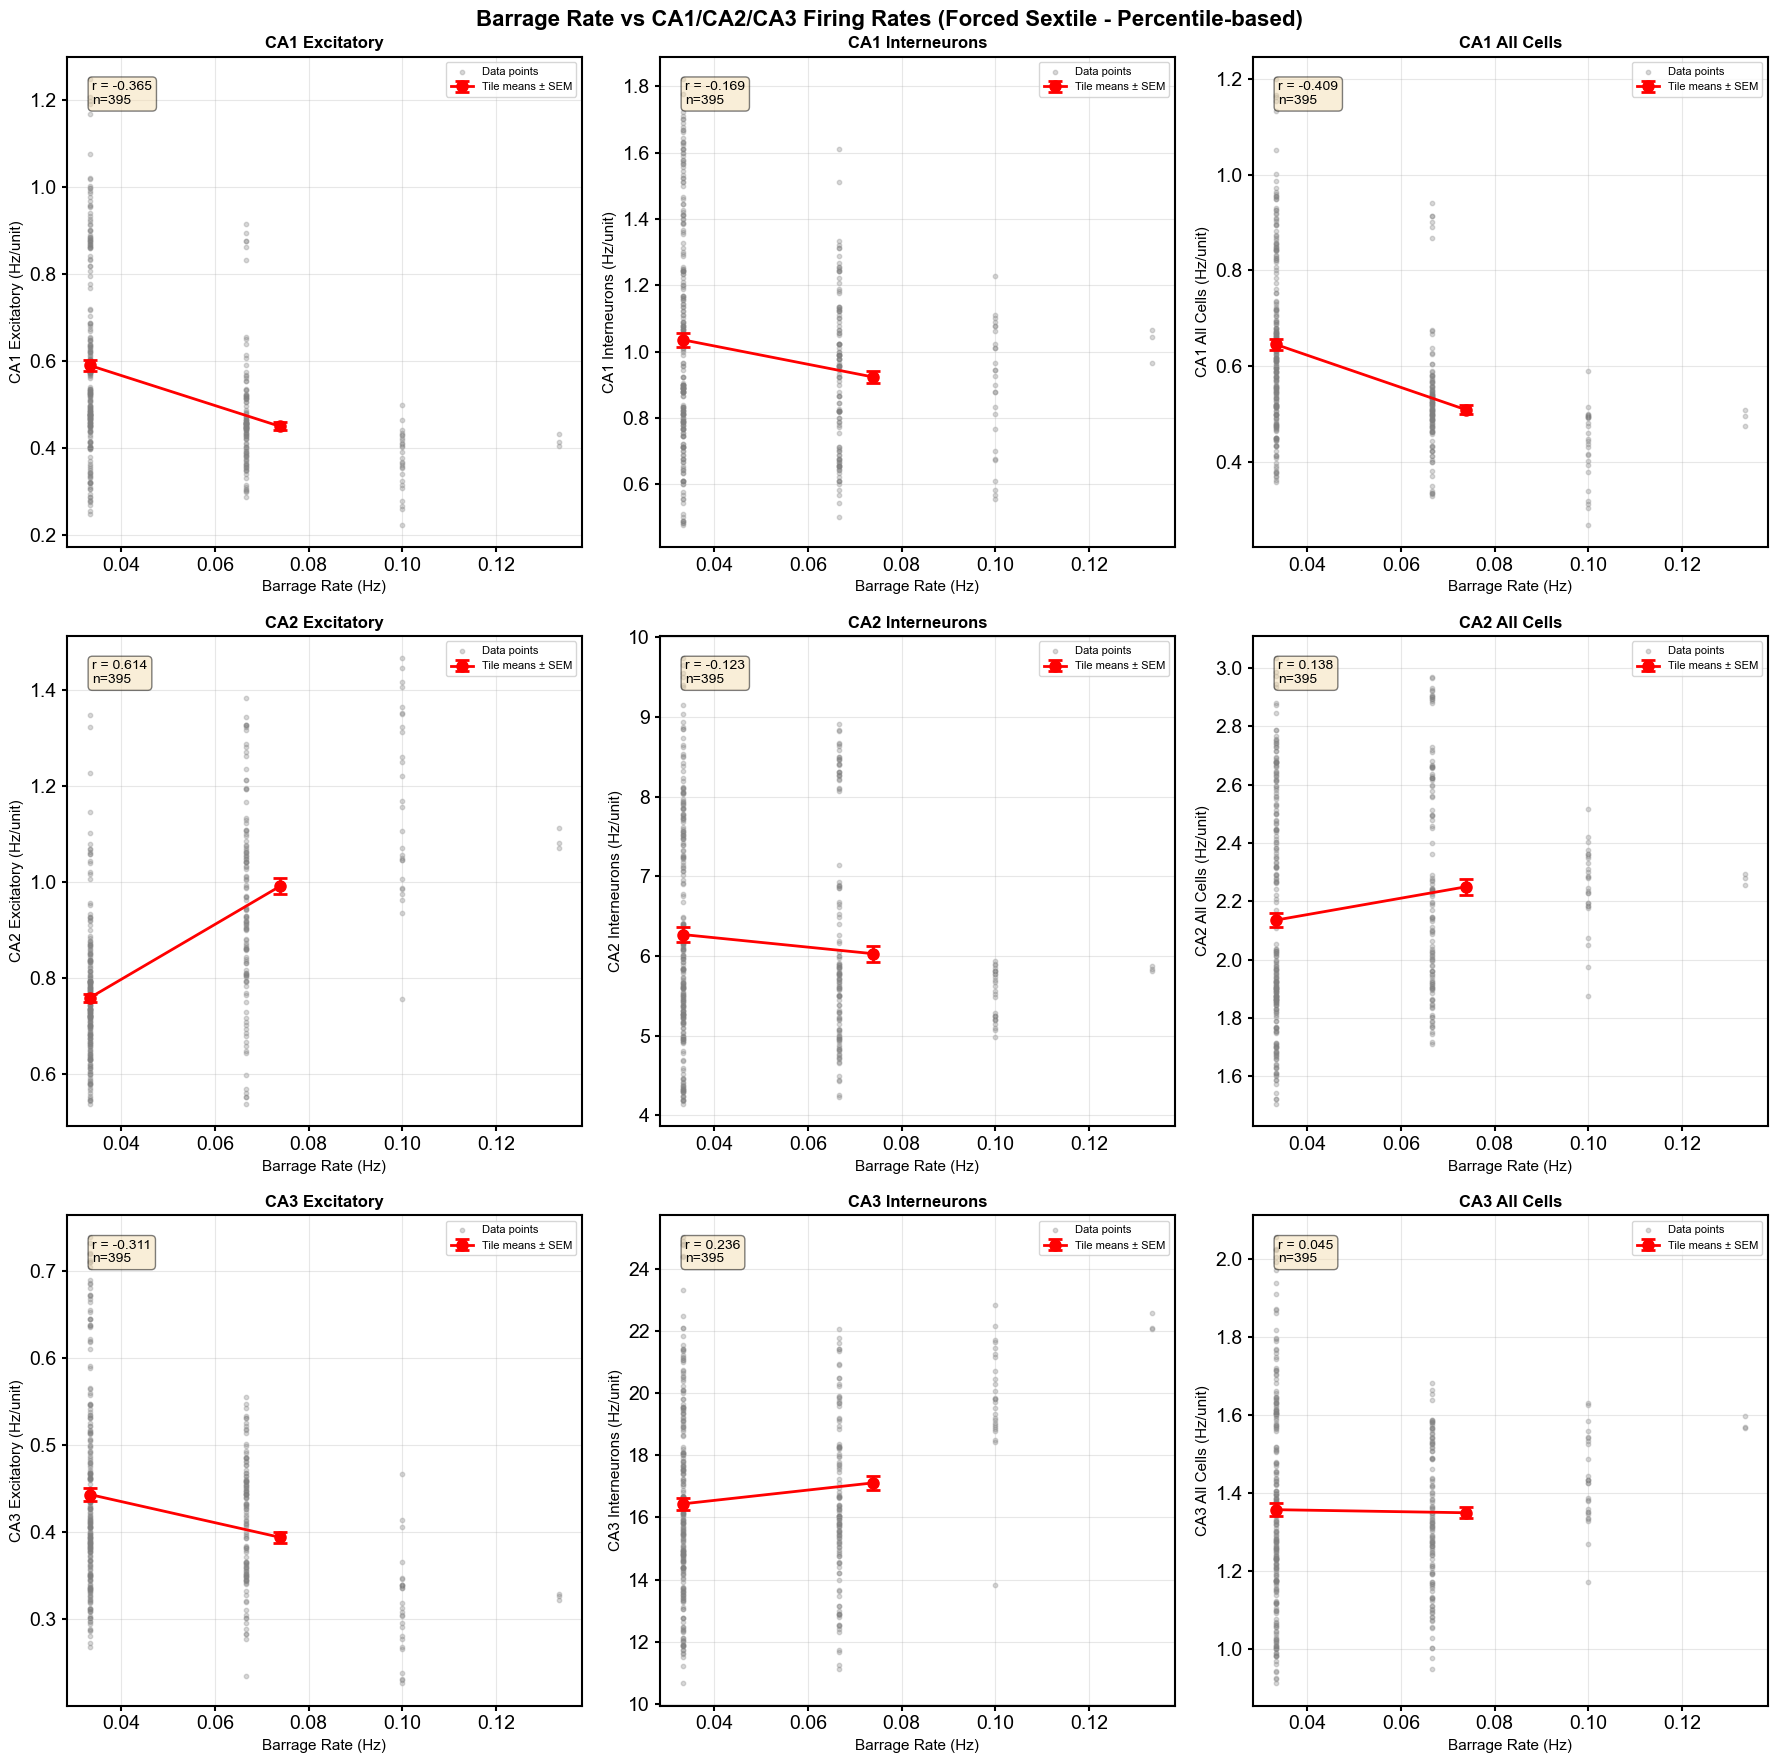


Forced sextile plot completed!

EQUAL-WIDTH SEXTILE:

CA1 Excitatory:
  Equal-width edges: [0.03333333 0.05       0.06666667 0.08333333 0.1        0.11666667
 0.13333333]
  Tile counts: [242, 0, 123, 0, 27, 3]

CA1 Interneurons:
  Equal-width edges: [0.03333333 0.05       0.06666667 0.08333333 0.1        0.11666667
 0.13333333]
  Tile counts: [242, 0, 123, 0, 27, 3]

CA1 All Cells:
  Equal-width edges: [0.03333333 0.05       0.06666667 0.08333333 0.1        0.11666667
 0.13333333]
  Tile counts: [242, 0, 123, 0, 27, 3]

CA2 Excitatory:
  Equal-width edges: [0.03333333 0.05       0.06666667 0.08333333 0.1        0.11666667
 0.13333333]
  Tile counts: [242, 0, 123, 0, 27, 3]

CA2 Interneurons:
  Equal-width edges: [0.03333333 0.05       0.06666667 0.08333333 0.1        0.11666667
 0.13333333]
  Tile counts: [242, 0, 123, 0, 27, 3]

CA2 All Cells:
  Equal-width edges: [0.03333333 0.05       0.06666667 0.08333333 0.1        0.11666667
 0.13333333]
  Tile counts: [242, 0, 123, 0, 27, 3]

C

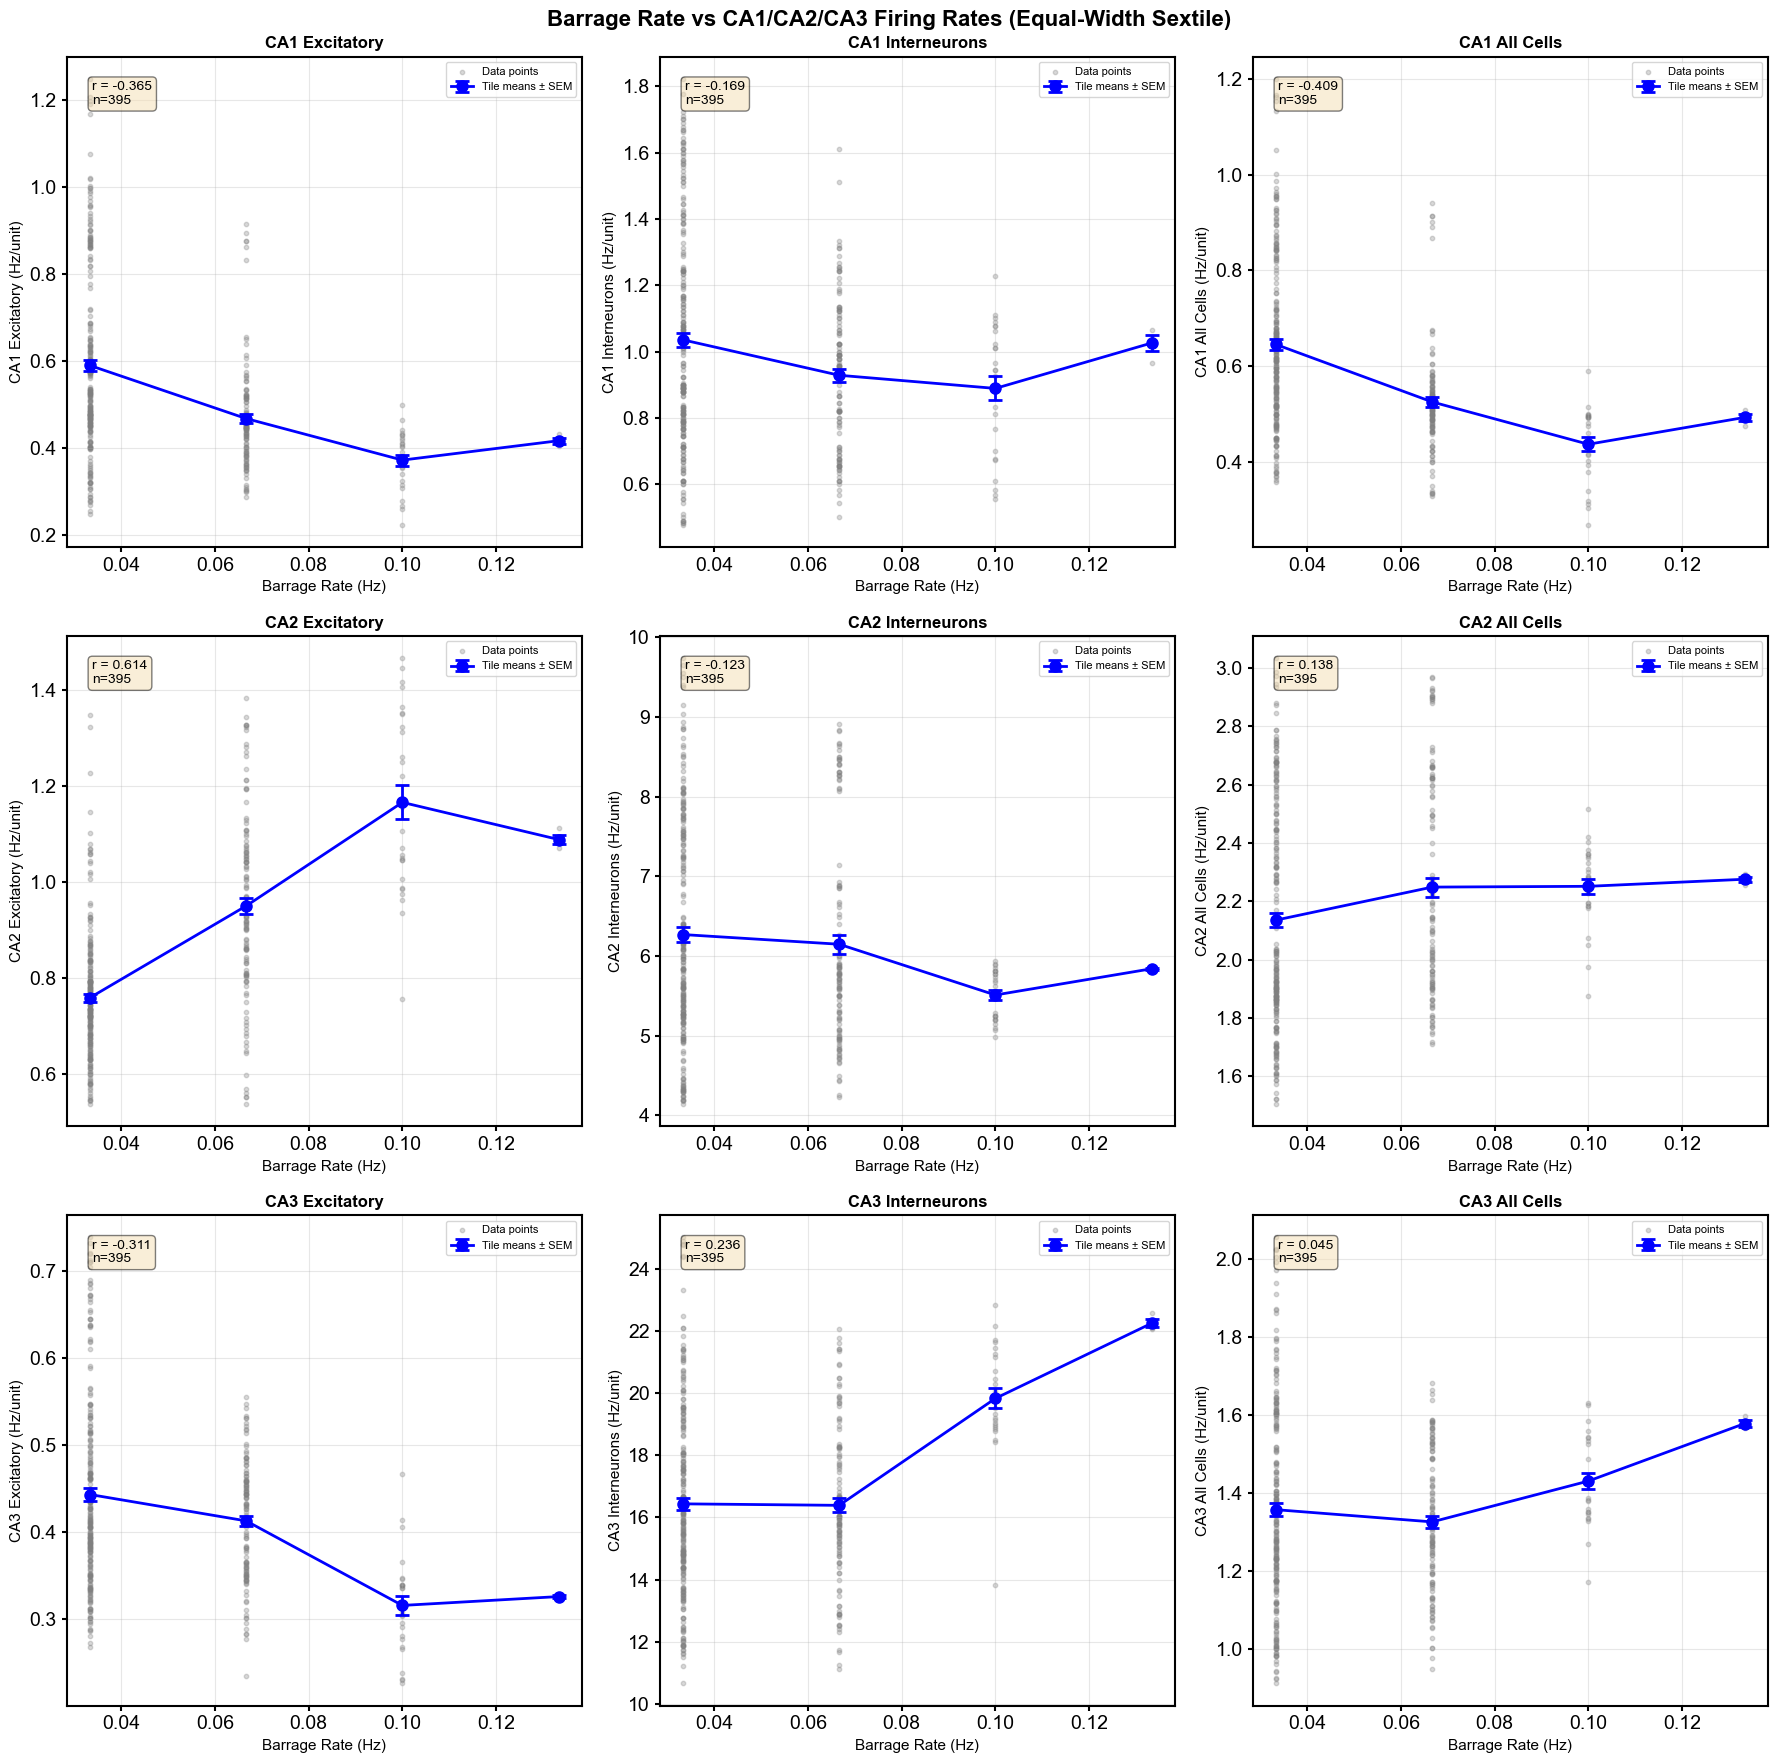


Equal-width sextile plot completed!


In [195]:
# Create 9-tile plot: Barrage rate vs CA1/CA2/CA3 Excitatory/Inhibitory firing rates
# With both forced sextile (percentile-based) and equal-width sextile
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import binned_statistic

# Filter out rows with zero barrage rate for better visualization
df_plot = ca1_complete_df[ca1_complete_df['barrage_rate'] > 0].copy()

print(f"Plotting {len(df_plot)} points with non-zero barrage rate")

# Create 9-tile figure (3 rows x 3 columns) - CA1, CA2, CA3
fig, axes = plt.subplots(3, 3, figsize=(18, 18))
fig.suptitle('Barrage Rate vs CA1/CA2/CA3 Firing Rates (Forced Sextile - Percentile-based)', fontsize=16, fontweight='bold')

# Define the columns to plot
plot_configs = [
    ('CA1_E_FR_per_unit', 'CA1 Excitatory', 0, 0),
    ('CA1_I_FR_per_unit', 'CA1 Interneurons', 0, 1),
    ('CA1_All_FR_per_unit', 'CA1 All Cells', 0, 2),
    ('CA2_E_FR_per_unit', 'CA2 Excitatory', 1, 0),
    ('CA2_I_FR_per_unit', 'CA2 Interneurons', 1, 1),
    ('CA2_All_FR_per_unit', 'CA2 All Cells', 1, 2),
    ('CA3_E_FR_per_unit', 'CA3 Excitatory', 2, 0),
    ('CA3_I_FR_per_unit', 'CA3 Interneurons', 2, 1),
    ('CA3_All_FR_per_unit', 'CA3 All Cells', 2, 2),
]

# Number of tiles for binning
n_tiles = 6

print("\n" + "="*60)
print("FORCED SEXTILE (Percentile-based binning):")
print("="*60)

for col_name, title, row, col in plot_configs:
    ax = axes[row, col]
    
    # Get data
    x = df_plot['barrage_rate'].values
    y = df_plot[col_name].values
    
    # Remove NaN values
    mask = ~(np.isnan(x) | np.isnan(y))
    x_clean = x[mask]
    y_clean = y[mask]
    
    if len(x_clean) == 0:
        ax.text(0.5, 0.5, 'No valid data', ha='center', va='center', transform=ax.transAxes)
        ax.set_title(title)
        continue
    
    # Scatter plot with transparency
    ax.scatter(x_clean, y_clean, alpha=0.3, s=10, color='gray', label='Data points')
    
    # FORCED SEXTILE: Create tiles based on barrage rate percentiles
    percentiles = np.linspace(0, 100, n_tiles + 1)
    tile_edges = np.percentile(x_clean, percentiles)
    
    print(f"\n{title}:")
    print(f"  Percentile edges: {tile_edges}")
    
    # Compute mean and SEM for each tile
    tile_means_x = []
    tile_means_y = []
    tile_sems_y = []
    tile_counts = []
    
    for i in range(n_tiles):
        mask_tile = (x_clean >= tile_edges[i]) & (x_clean < tile_edges[i+1])
        if i == n_tiles - 1:  # Include right edge for last tile
            mask_tile = (x_clean >= tile_edges[i]) & (x_clean <= tile_edges[i+1])
        
        if np.sum(mask_tile) > 0:
            tile_means_x.append(np.mean(x_clean[mask_tile]))
            tile_means_y.append(np.mean(y_clean[mask_tile]))
            tile_sems_y.append(np.std(y_clean[mask_tile]) / np.sqrt(np.sum(mask_tile)))
            tile_counts.append(np.sum(mask_tile))
    
    print(f"  Tile counts: {tile_counts}")
    
    tile_means_x = np.array(tile_means_x)
    tile_means_y = np.array(tile_means_y)
    tile_sems_y = np.array(tile_sems_y)
    
    # Plot tile means with error bars
    ax.errorbar(tile_means_x, tile_means_y, yerr=tile_sems_y, 
                fmt='o-', color='red', linewidth=2, markersize=8, 
                capsize=5, capthick=2, label='Tile means ± SEM')
    
    # Labels and title
    ax.set_xlabel('Barrage Rate (Hz)', fontsize=11)
    ax.set_ylabel(f'{title} (Hz/unit)', fontsize=11)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.legend(fontsize=8, loc='best')
    ax.grid(True, alpha=0.3)
    
    # Add correlation info
    corr = np.corrcoef(x_clean, y_clean)[0, 1]
    ax.text(0.05, 0.95, f'r = {corr:.3f}\nn={len(x_clean)}', 
            transform=ax.transAxes, fontsize=10, 
            verticalalignment='top', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()
plt.show()

print("\n" + "="*60)
print("Forced sextile plot completed!")
print("="*60)

# ========================================================================
# EQUAL-WIDTH SEXTILE
# ========================================================================

fig2, axes2 = plt.subplots(3, 3, figsize=(18, 18))
fig2.suptitle('Barrage Rate vs CA1/CA2/CA3 Firing Rates (Equal-Width Sextile)', fontsize=16, fontweight='bold')

print("\n" + "="*60)
print("EQUAL-WIDTH SEXTILE:")
print("="*60)

for col_name, title, row, col in plot_configs:
    ax = axes2[row, col]
    
    # Get data
    x = df_plot['barrage_rate'].values
    y = df_plot[col_name].values
    
    # Remove NaN values
    mask = ~(np.isnan(x) | np.isnan(y))
    x_clean = x[mask]
    y_clean = y[mask]
    
    if len(x_clean) == 0:
        ax.text(0.5, 0.5, 'No valid data', ha='center', va='center', transform=ax.transAxes)
        ax.set_title(title)
        continue
    
    # Scatter plot with transparency
    ax.scatter(x_clean, y_clean, alpha=0.3, s=10, color='gray', label='Data points')
    
    # EQUAL-WIDTH SEXTILE: Create tiles based on equal widths
    x_min, x_max = x_clean.min(), x_clean.max()
    tile_edges_equal = np.linspace(x_min, x_max, n_tiles + 1)
    
    print(f"\n{title}:")
    print(f"  Equal-width edges: {tile_edges_equal}")
    
    # Compute mean and SEM for each tile
    tile_means_x_eq = []
    tile_means_y_eq = []
    tile_sems_y_eq = []
    tile_counts_eq = []
    
    for i in range(n_tiles):
        mask_tile = (x_clean >= tile_edges_equal[i]) & (x_clean < tile_edges_equal[i+1])
        if i == n_tiles - 1:  # Include right edge for last tile
            mask_tile = (x_clean >= tile_edges_equal[i]) & (x_clean <= tile_edges_equal[i+1])
        
        if np.sum(mask_tile) > 0:
            tile_means_x_eq.append(np.mean(x_clean[mask_tile]))
            tile_means_y_eq.append(np.mean(y_clean[mask_tile]))
            tile_sems_y_eq.append(np.std(y_clean[mask_tile]) / np.sqrt(np.sum(mask_tile)))
            tile_counts_eq.append(np.sum(mask_tile))
        else:
            # Empty tile - use bin center with NaN
            tile_means_x_eq.append((tile_edges_equal[i] + tile_edges_equal[i+1]) / 2)
            tile_means_y_eq.append(np.nan)
            tile_sems_y_eq.append(np.nan)
            tile_counts_eq.append(0)
    
    print(f"  Tile counts: {tile_counts_eq}")
    
    tile_means_x_eq = np.array(tile_means_x_eq)
    tile_means_y_eq = np.array(tile_means_y_eq)
    tile_sems_y_eq = np.array(tile_sems_y_eq)
    
    # Plot tile means with error bars (skip NaN values)
    valid_mask = ~np.isnan(tile_means_y_eq)
    ax.errorbar(tile_means_x_eq[valid_mask], tile_means_y_eq[valid_mask], 
                yerr=tile_sems_y_eq[valid_mask], 
                fmt='o-', color='blue', linewidth=2, markersize=8, 
                capsize=5, capthick=2, label='Tile means ± SEM')
    
    # Labels and title
    ax.set_xlabel('Barrage Rate (Hz)', fontsize=11)
    ax.set_ylabel(f'{title} (Hz/unit)', fontsize=11)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.legend(fontsize=8, loc='best')
    ax.grid(True, alpha=0.3)
    
    # Add correlation info
    corr = np.corrcoef(x_clean, y_clean)[0, 1]
    ax.text(0.05, 0.95, f'r = {corr:.3f}\nn={len(x_clean)}', 
            transform=ax.transAxes, fontsize=10, 
            verticalalignment='top', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()
plt.show()

print("\n" + "="*60)
print("Equal-width sextile plot completed!")
print("="*60)

In [196]:
# Save ca1_complete_df as pickle file
import pickle
import os

# Define save directory
save_dir = r"D:\Documents\GitHub\Sleep_criticaltiy\data\rats\barr_CA2_CA3"

# Create directory if it doesn't exist
if not os.path.exists(save_dir):
    os.makedirs(save_dir)
    print(f"Created directory: {save_dir}")

# Create filename from animal_name and day
filename = f"{animal_name}_{day}.pkl"
save_path = os.path.join(save_dir, filename)

# Save dataframe
with open(save_path, 'wb') as f:
    pickle.dump(ca1_complete_df, f)

print(f"\n✅ Saved ca1_complete_df to: {save_path}")
print(f"📊 Shape: {ca1_complete_df.shape}")
print(f"📊 Columns: {list(ca1_complete_df.columns)}")
print(f"📊 File size: {os.path.getsize(save_path) / 1024:.2f} KB")


✅ Saved ca1_complete_df to: D:\Documents\GitHub\Sleep_criticaltiy\data\rats\barr_CA2_CA3\AYA10_day34.pkl
📊 Shape: (5825, 15)
📊 Columns: ['center_s', 'd2', 'd2_err', 'state', 'CA1_All_FR_per_unit', 'CA1_E_FR_per_unit', 'CA1_I_FR_per_unit', 'CA2_All_FR_per_unit', 'CA2_E_FR_per_unit', 'CA2_I_FR_per_unit', 'CA3_All_FR_per_unit', 'CA3_E_FR_per_unit', 'CA3_I_FR_per_unit', 'barrage_rate', 'ripple_rate']
📊 File size: 678.38 KB


Found 9 pkl files
Loaded: AB4_day07.pkl - Shape: (5786, 15)
Loaded: AB4_day08.pkl - Shape: (4407, 15)
Loaded: AB4_day09.pkl - Shape: (8028, 15)
Loaded: AB4_day11.pkl - Shape: (8237, 15)
Loaded: AYA10_day25.pkl - Shape: (5778, 15)
Loaded: AYA10_day27.pkl - Shape: (8177, 15)
Loaded: AYA10_day31.pkl - Shape: (7553, 15)
Loaded: AYA10_day34.pkl - Shape: (5825, 15)
Loaded: AYA7_day25.pkl - Shape: (9610, 14)

Total files loaded: 9

Computing Z-scored statistics using method: EQUAL_WIDTH...

Processing: AB4_day07.pkl
  CA1_E_FR_per_unit: 2095 points, tile counts: [1320  375  191  161   34   14]
  CA1_I_FR_per_unit: 2095 points, tile counts: [1320  375  191  161   34   14]
  CA1_All_FR_per_unit: 2095 points, tile counts: [1320  375  191  161   34   14]
  CA2_E_FR_per_unit: 2095 points, tile counts: [1320  375  191  161   34   14]
  CA2_I_FR_per_unit: 2095 points, tile counts: [1320  375  191  161   34   14]
  CA2_All_FR_per_unit: 2095 points, tile counts: [1320  375  191  161   34   14]
  CA3_E

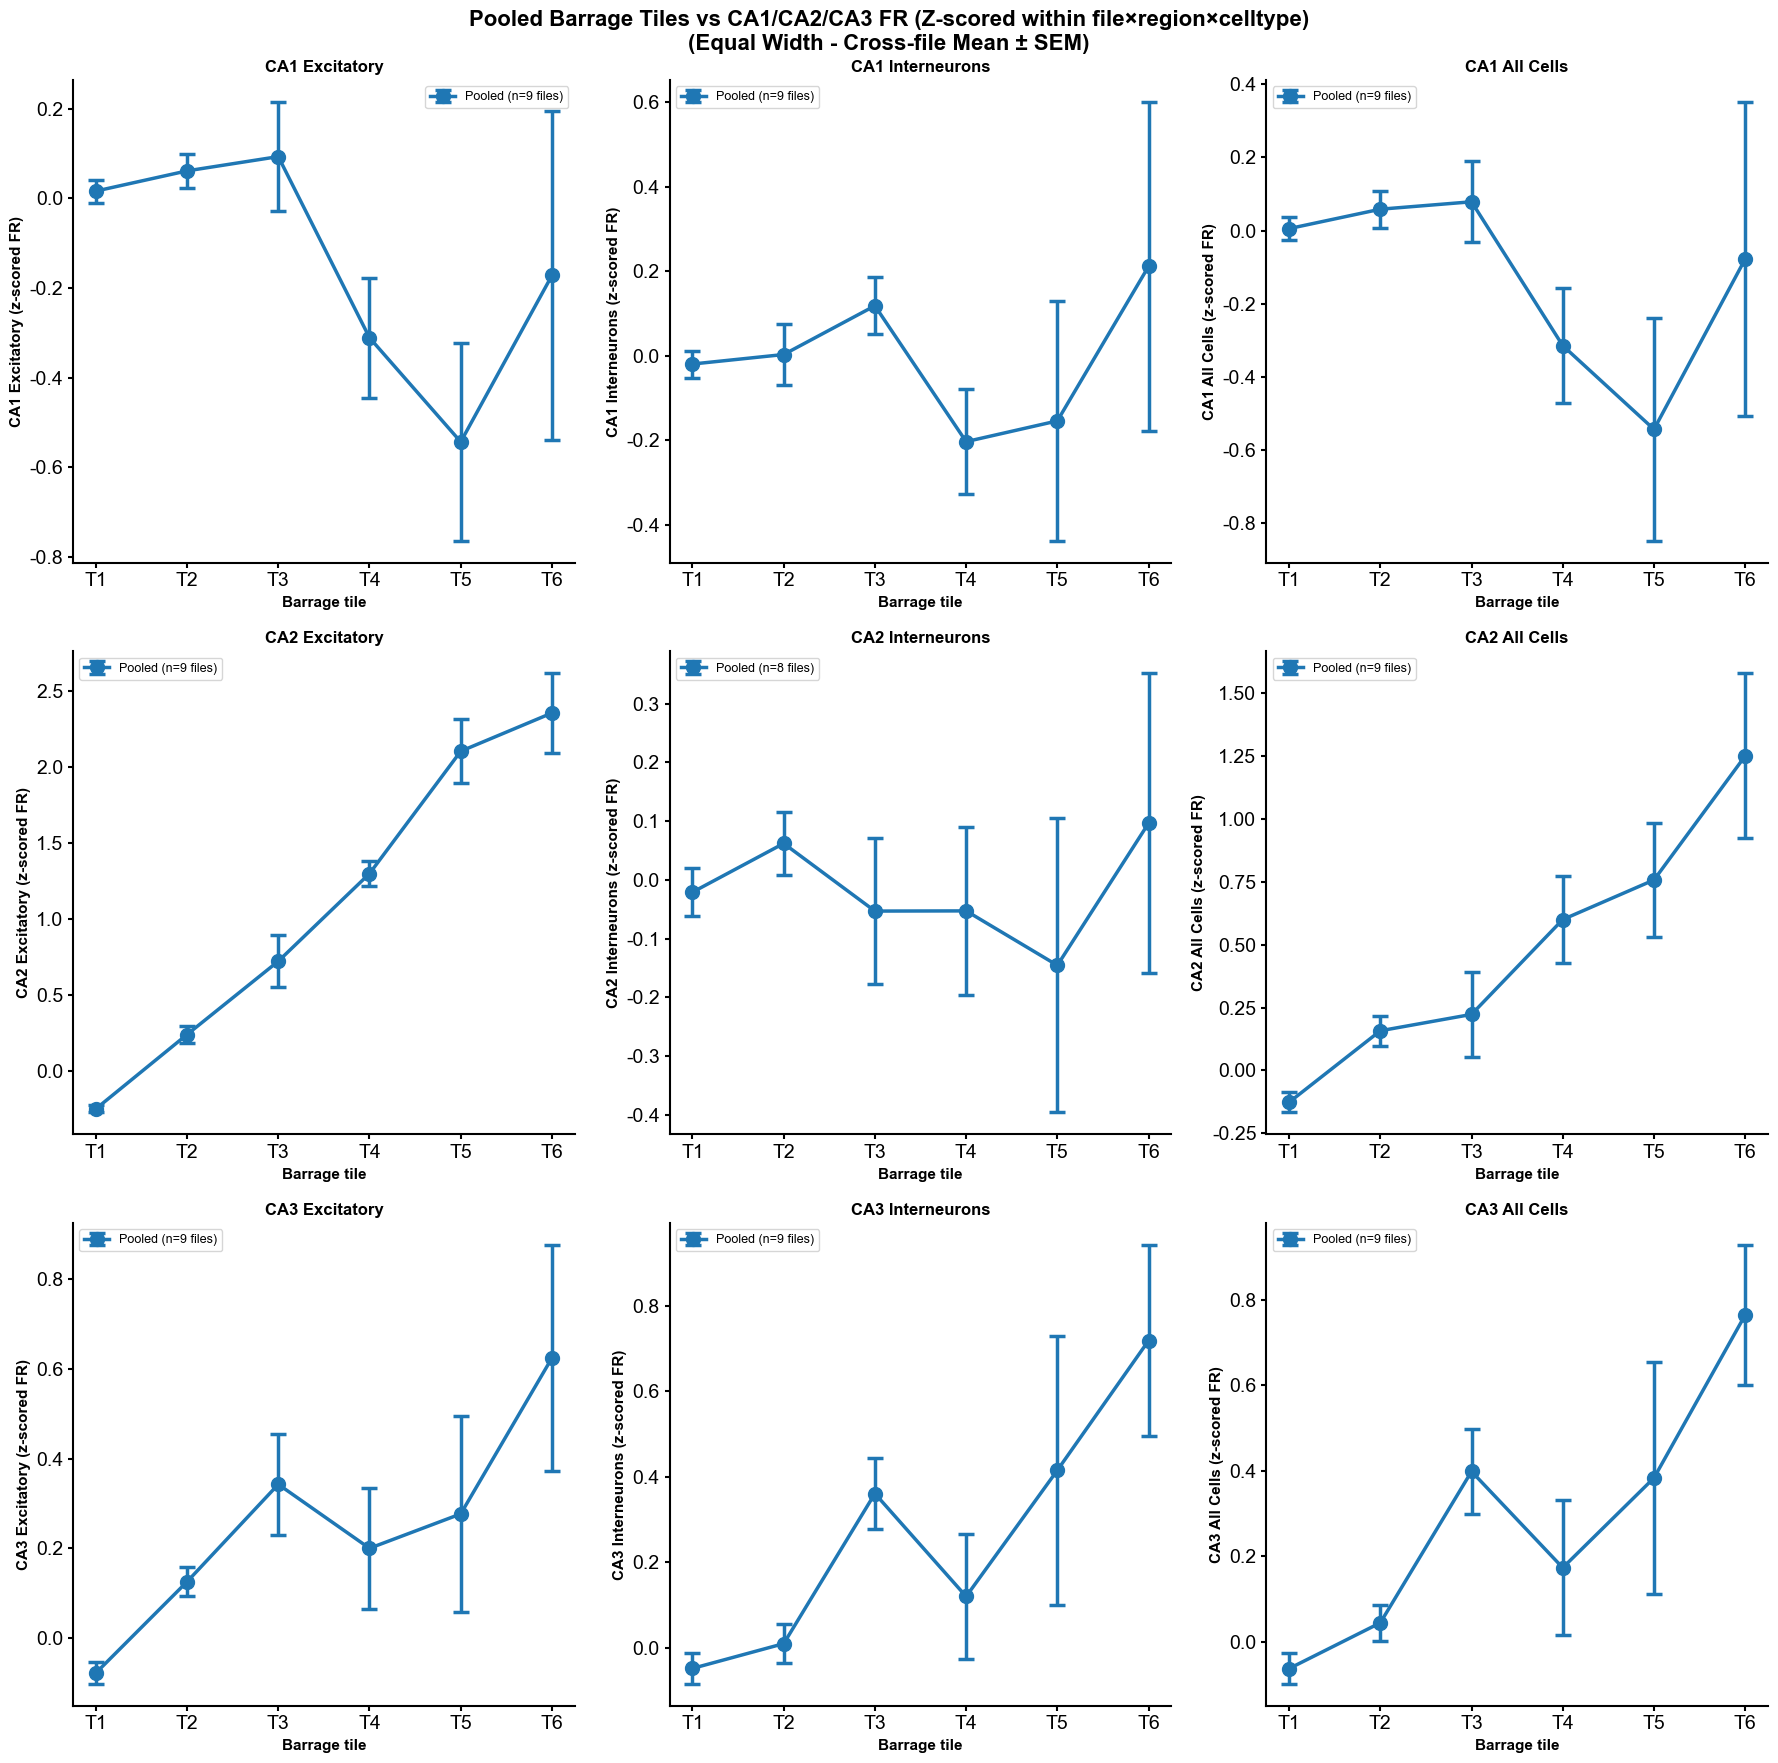


Z-score analysis complete!


In [7]:
import pickle
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from glob import glob

# ==========================================
# CONFIGURATION
# ==========================================
save_dir = r"D:\Documents\GitHub\Sleep_criticaltiy\data\rats\barr_CA2_CA3"

BINNING_METHOD = 'equal_width'   # 'equal_count' (forced sextile) or 'equal_width'
n_tiles = 6

fr_columns = [
    'CA1_E_FR_per_unit', 'CA1_I_FR_per_unit', 'CA1_All_FR_per_unit',
    'CA2_E_FR_per_unit', 'CA2_I_FR_per_unit', 'CA2_All_FR_per_unit',
    'CA3_E_FR_per_unit', 'CA3_I_FR_per_unit', 'CA3_All_FR_per_unit'
]

# ==========================================
# LOAD DATA
# ==========================================
pkl_files = glob(os.path.join(save_dir, "*.pkl"))
print(f"Found {len(pkl_files)} pkl files")
print("="*60)

all_dfs = []
for pkl_file in pkl_files:
    with open(pkl_file, 'rb') as f:
        df = pickle.load(f)
    filename = os.path.basename(pkl_file)
    print(f"Loaded: {filename} - Shape: {df.shape}")
    all_dfs.append(df)

print("\n" + "="*60)
print(f"Total files loaded: {len(all_dfs)}")
print("="*60)

# ==========================================
# HELPERS
# ==========================================

def zscore_within_vector(y):
    """Z-score a 1D array; returns NaNs if std=0 or too few points."""
    y = np.asarray(y, float)
    mu = np.nanmean(y)
    sd = np.nanstd(y)
    if not np.isfinite(sd) or sd == 0:
        return np.full_like(y, np.nan, dtype=float)
    return (y - mu) / sd

def compute_binned_stats_zscore(df, fr_column, n_tiles=6, method='equal_width'):
    """
    For ONE FILE and ONE fr_column:
      1) keep barrage_rate > 0
      2) drop NaNs in x and y
      3) z-score y within this file+region+celltype (i.e., within this column)
      4) compute sextile (equal_count) OR equal_width bins on x
      5) return per-tile means of x and z(y)
    """
    if ('barrage_rate' not in df.columns) or (fr_column not in df.columns):
        return None

    df_filtered = df[(df["state"] == "NREM")].copy()
    if len(df_filtered) == 0:
        return None

    x = df_filtered['barrage_rate'].to_numpy(dtype=float)
    y = df_filtered[fr_column].to_numpy(dtype=float)

    mask = ~(np.isnan(x) | np.isnan(y))
    x_clean = x[mask]
    y_clean = y[mask]
    if len(x_clean) < 3:
        return None

    # --- z-score y within this file+region+celltype (i.e., within this column) ---
    y_z = zscore_within_vector(y_clean)
    # If zscore failed (std==0), bail
    if np.all(np.isnan(y_z)):
        return None

    # --- bin edges from x_clean ---
    if method == 'equal_count':
        # force sextiles by percentiles
        percentiles = np.linspace(0, 100, n_tiles + 1)
        tile_edges = np.percentile(x_clean, percentiles)

        # Important: if barrage_rate has many ties, percentiles can repeat -> empty bins.
        # We'll still handle via NaNs/0 counts below.
    elif method == 'equal_width':
        tile_edges = np.linspace(np.min(x_clean), np.max(x_clean), n_tiles + 1)
    else:
        raise ValueError(f"Unknown method: {method}")

    tile_means_x = []
    tile_means_yz = []
    tile_counts = []

    for i in range(n_tiles):
        if i == n_tiles - 1:
            mask_tile = (x_clean >= tile_edges[i]) & (x_clean <= tile_edges[i+1])
        else:
            mask_tile = (x_clean >= tile_edges[i]) & (x_clean < tile_edges[i+1])

        count = int(np.sum(mask_tile))
        tile_counts.append(count)

        if count > 0:
            tile_means_x.append(np.mean(x_clean[mask_tile]))
            tile_means_yz.append(np.mean(y_z[mask_tile]))
        else:
            tile_means_x.append(np.nan)
            tile_means_yz.append(np.nan)

    return {
        "tile_means_x": np.array(tile_means_x, float),
        "tile_means_y": np.array(tile_means_yz, float),  # <-- z-scored means
        "tile_counts": np.array(tile_counts, int),
        "n_points": int(len(x_clean))
    }

# ==========================================
# COMPUTE PER-FILE STATS THEN POOL
# ==========================================
print("\n" + "="*60)
print(f"Computing Z-scored statistics using method: {BINNING_METHOD.upper()}...")
print("="*60)

pooled_data = {col: [] for col in fr_columns}

for idx, df in enumerate(all_dfs):
    filename = os.path.basename(pkl_files[idx])
    print(f"\nProcessing: {filename}")

    for col in fr_columns:
        stats = compute_binned_stats_zscore(df, col, n_tiles=n_tiles, method=BINNING_METHOD)
        if stats is not None:
            pooled_data[col].append(stats)
            print(f"  {col}: {stats['n_points']} points, tile counts: {stats['tile_counts']}")
        else:
            print(f"  {col}: skipped (missing/empty/zero-std)")

print("\n" + "="*60)
print("Computing pooled statistics (mean ± SEM across files per tile)...")
print("="*60)

pooled_stats = {}

for col in fr_columns:
    if len(pooled_data[col]) == 0:
        print(f"{col}: No data")
        continue

    all_tile_means_x = np.array([s["tile_means_x"] for s in pooled_data[col]], float)  # files x tiles
    all_tile_means_y = np.array([s["tile_means_y"] for s in pooled_data[col]], float)  # files x tiles (z)

    pooled_mean_x = np.nanmean(all_tile_means_x, axis=0)
    pooled_mean_y = np.nanmean(all_tile_means_y, axis=0)

    n_valid = np.sum(~np.isnan(all_tile_means_y), axis=0)
    pooled_std = np.nanstd(all_tile_means_y, axis=0)

    with np.errstate(divide='ignore', invalid='ignore'):
        pooled_sem = pooled_std / np.sqrt(n_valid)

    pooled_stats[col] = {
        "mean_x": pooled_mean_x,
        "mean_y": pooled_mean_y,
        "sem_y": pooled_sem,
        "n_files": len(pooled_data[col]),
        "n_valid": n_valid
    }
    print(f"{col}: pooled from {len(pooled_data[col])} files")

# ==========================================
# PLOTTING (Z-SCORED FR)
# ==========================================
# ==========================================
print("\n" + "="*60)
print("Creating pooled plots (z-scored FR, x = tile)...")
print("="*60)

fig, axes = plt.subplots(3, 3, figsize=(18, 18))
method_title = "Equal Width" if BINNING_METHOD == 'equal_width' else "Forced Sextile (Equal Count)"
fig.suptitle(
    f'Pooled Barrage Tiles vs CA1/CA2/CA3 FR (Z-scored within file×region×celltype)\n'
    f'({method_title} - Cross-file Mean ± SEM)',
    fontsize=16, fontweight='bold'
)

plot_configs = [
    ('CA1_E_FR_per_unit', 'CA1 Excitatory', 0, 0),
    ('CA1_I_FR_per_unit', 'CA1 Interneurons', 0, 1),
    ('CA1_All_FR_per_unit', 'CA1 All Cells', 0, 2),
    ('CA2_E_FR_per_unit', 'CA2 Excitatory', 1, 0),
    ('CA2_I_FR_per_unit', 'CA2 Interneurons', 1, 1),
    ('CA2_All_FR_per_unit', 'CA2 All Cells', 1, 2),
    ('CA3_E_FR_per_unit', 'CA3 Excitatory', 2, 0),
    ('CA3_I_FR_per_unit', 'CA3 Interneurons', 2, 1),
    ('CA3_All_FR_per_unit', 'CA3 All Cells', 2, 2),
]

tile_ids = np.arange(1, n_tiles + 1)

for col_name, title, r, c in plot_configs:
    ax = axes[r, c]

    if col_name not in pooled_stats:
        ax.text(0.5, 0.5, 'No data', ha='center', va='center', transform=ax.transAxes)
        ax.set_title(title)
        continue

    st = pooled_stats[col_name]

    # valid tiles are those with a pooled mean (and sem) defined
    valid = np.isfinite(st["mean_y"])  # sem can be nan if n_valid==0; mean_y is the key
    x_plot = tile_ids[valid]
    y_plot = st["mean_y"][valid]
    sem_plot = st["sem_y"][valid]

    if len(x_plot) == 0:
        ax.text(0.5, 0.5, 'No valid tiles', ha='center', va='center', transform=ax.transAxes)
        ax.set_title(title)
        continue

    ax.errorbar(
        x_plot, y_plot, yerr=sem_plot,
        fmt='o-', linewidth=2.5, markersize=10,
        capsize=6, capthick=2.5,
        label=f'Pooled (n={st["n_files"]} files)'
    )

    ax.set_xlabel('Barrage tile', fontsize=11, fontweight='bold')
    ax.set_ylabel(f'{title} (z-scored FR)', fontsize=11, fontweight='bold')
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.legend(fontsize=9, loc='best')

    # nice tile tick labels
    ax.set_xticks(tile_ids)
    ax.set_xticklabels([f"T{i}" for i in tile_ids])

    ax.grid(False)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

print("\n" + "="*60)
print("Z-score analysis complete!")
print("="*60)


C:\Users\Cornell\AppData\Local\Temp\ipykernel_50008\3979787839.py:74: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


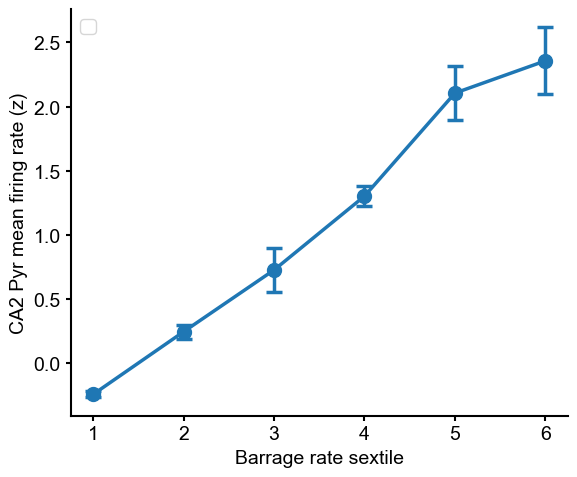

Weighted slope = 0.523 ± 0.016 (SE), t=33.47, p=4.76e-06, n=6
Pearson r = 0.994, p = 5.06e-05, n = 6


Text(0.5, 1.0, 'CA2 Excitatory (Pearson r=0.99, p=5.1e-05)')

In [8]:
import matplotlib as mpl
import scipy.stats as spstats
# Global font: prefer Arial, with safe fallbacks
mpl.rcParams['svg.fonttype'] = 'none' 
mpl.rcParams['text.usetex'] = False
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = [
    'Helvetica Neue', 'Helvetica', 'Arial', 'Liberation Sans', 'DejaVu Sans'
]

# Mathtext to match (works if those faces exist on your system)
mpl.rcParams['mathtext.fontset'] = 'custom'
mpl.rcParams['mathtext.rm'] = 'Helvetica Neue'   # or 'Helvetica'
mpl.rcParams['mathtext.it'] = 'Helvetica Neue:italic'
mpl.rcParams['mathtext.bf'] = 'Helvetica Neue:bold'

# (optional) sizes + minus sign
mpl.rcParams['font.size'] = 16
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams['axes.unicode_minus'] = False

# Global sizes (tweak to taste)
mpl.rcParams['font.size'] = 14
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams["axes.linewidth"] = 1.5       # spine width
mpl.rcParams["xtick.major.width"] =1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5
mpl.rcParams["axes.linewidth"] = 1.5       # spine width
mpl.rcParams["xtick.major.width"] =1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5

col_name = "CA2_E_FR_per_unit"
title = "CA2 Excitatory"

fig, ax = plt.subplots(figsize=(6, 5))

st = pooled_stats[col_name]

tile_ids = np.arange(1, n_tiles + 1)
valid = np.isfinite(st["mean_y"])

x_plot = tile_ids[valid]
y_plot = st["mean_y"][valid]
sem_plot = st["sem_y"][valid]

ax.errorbar(
    x_plot, y_plot, yerr=sem_plot,
    fmt='o-', linewidth=2.5, markersize=10,
    capsize=6, capthick=2.5,label=None
)

ax.set_xlabel("Barrage rate sextile")
ax.set_ylabel("CA2 Pyr mean firing rate (z)")

ax.set_xticks(tile_ids)
ax.set_xticklabels([f"{i}" for i in tile_ids])

ax.grid(False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend()

plt.tight_layout()
save_path=r"D:\Documents\GitHub\Sleep_criticaltiy\reports\new_planc\supplementary\S3_model_pooled_CA2_E_FR_per_unit_vs_barrage_tiles.svg"
plt.savefig(save_path, dpi=300)
plt.show()
w = 1.0 / np.clip(sem_plot.astype(float), 1e-12, np.inf)**2

# weighted linear fit: y = b0 + b1 x
b1, b0 = np.polyfit(x_plot.astype(float), y_plot.astype(float), deg=1, w=np.sqrt(w))

# get an approximate p-value for slope using weighted regression
# (using effective residual variance)
yhat = b0 + b1 * x_plot
resid = y_plot - yhat
dof = len(x_plot) - 2
s2 = np.sum(w * resid**2) / dof
Sxx = np.sum(w * (x_plot - np.average(x_plot, weights=w))**2)
se_b1 = np.sqrt(s2 / Sxx)
t = b1 / se_b1
p_slope = 2 * spstats.t.sf(np.abs(t), dof)

print(f"Weighted slope = {b1:.3f} ± {se_b1:.3f} (SE), t={t:.2f}, p={p_slope:.3g}, n={len(x_plot)}")
from scipy import stats
import numpy as np

# x_plot, y_plot already defined
r, p = stats.pearsonr(x_plot.astype(float), y_plot.astype(float))
print(f"Pearson r = {r:.3f}, p = {p:.3g}, n = {len(x_plot)}")

# optional: add to title
ax.set_title(f"{title} (Pearson r={r:.2f}, p={p:.2g})")


In [200]:
"""
Fit ALL FEATURES with robust fallbacks:
1) Try random-slope LMM: yz ~ tile_c + (1 + tile_c | file)
2) If not converged / fails -> random-intercept LMM: yz ~ tile_c + (1 | file)
3) If still fails -> clustered OLS: yz ~ tile_c with SE clustered by file_id

Outputs a summary table across all features, plus a "nonconverged" table.

Assumes you already have:
- save_dir, BINNING_METHOD, n_tiles, MIN_WINDOWS_PER_FILE, fr_columns
- and your PKLs contain 'barrage_rate' + FR columns.
"""

import os
import pickle
import numpy as np
import pandas as pd
from glob import glob

import statsmodels.formula.api as smf
from scipy.stats import norm

# ==========================================
# CONFIGURATION
# ==========================================
save_dir = r"D:\Documents\GitHub\Sleep_criticaltiy\data\rats\barr_CA2_CA3"
BINNING_METHOD = "equal_width"   # "equal_count" or "equal_width"
n_tiles = 6
MIN_WINDOWS_PER_FILE = 10
USE_RANDOM_SLOPE_FIRST = True

fr_columns = [
    'CA1_E_FR_per_unit', 'CA1_I_FR_per_unit', 'CA1_All_FR_per_unit',
    'CA2_E_FR_per_unit', 'CA2_I_FR_per_unit', 'CA2_All_FR_per_unit',
    'CA3_E_FR_per_unit', 'CA3_I_FR_per_unit', 'CA3_All_FR_per_unit'
]

# ==========================================
# HELPERS
# ==========================================
def zscore_within_vector(y):
    y = np.asarray(y, float)
    mu = np.nanmean(y)
    sd = np.nanstd(y)
    if (not np.isfinite(sd)) or (sd == 0):
        return np.full_like(y, np.nan, dtype=float)
    return (y - mu) / sd

def assign_tiles_within_file(x, n_tiles=6, method="equal_width"):
    x = np.asarray(x, float)
    if len(x) == 0:
        return np.array([], dtype=int)

    if method == "equal_count":
        edges = np.percentile(x, np.linspace(0, 100, n_tiles + 1))
    elif method == "equal_width":
        edges = np.linspace(np.min(x), np.max(x), n_tiles + 1)
    else:
        raise ValueError(method)

    tile = np.zeros(len(x), dtype=int)
    for i in range(n_tiles):
        if i == n_tiles - 1:
            m = (x >= edges[i]) & (x <= edges[i+1])
        else:
            m = (x >= edges[i]) & (x < edges[i+1])
        tile[m] = i + 1
    return tile

def make_long_points_for_feature(df, fr_col, file_id, n_tiles=6, method="equal_width"):
    if "barrage_rate" not in df.columns or fr_col not in df.columns:
        return None

    dff = df[df["state"] == "NREM"].copy()
    if len(dff) == 0:
        return None

    x = dff["barrage_rate"].to_numpy(float)
    y = dff[fr_col].to_numpy(float)
    m = ~(np.isnan(x) | np.isnan(y))
    x = x[m]; y = y[m]
    if len(x) < 5:
        return None

    yz = zscore_within_vector(y)
    if np.all(np.isnan(yz)):
        return None

    tile = assign_tiles_within_file(x, n_tiles=n_tiles, method=method)

    out = pd.DataFrame({"file_id": file_id, "tile": tile, "yz": yz})
    out = out[(out["tile"] >= 1) & np.isfinite(out["yz"])].copy()
    return out if len(out) else None

def _wald_p_from_slope_se(slope, se):
    if (not np.isfinite(slope)) or (not np.isfinite(se)) or se == 0:
        return np.nan, np.nan
    z = slope / se
    p = 2 * (1 - norm.cdf(abs(z)))
    return z, p

def fit_rs_lmm(df_long):
    d = df_long.dropna(subset=["yz", "tile", "file_id"]).copy()
    d["tile_c"] = d["tile"] - d["tile"].mean()
    m = smf.mixedlm("yz ~ tile_c", data=d, groups=d["file_id"], re_formula="~tile_c")
    res = m.fit(reml=False, method="lbfgs", maxiter=800)
    slope = res.params.get("tile_c", np.nan)
    se = res.bse.get("tile_c", np.nan)
    z, p = _wald_p_from_slope_se(slope, se)
    return {
        "fit": "RS_LMM",
        "slope_per_tile": slope,
        "se": se,
        "z": z,
        "p": p,
        "converged": bool(getattr(res, "converged", True)),
        "aic": float(res.aic) if hasattr(res, "aic") else np.nan,
        "bic": float(res.bic) if hasattr(res, "bic") else np.nan,
    }

def fit_ri_lmm(df_long):
    d = df_long.dropna(subset=["yz", "tile", "file_id"]).copy()
    d["tile_c"] = d["tile"] - d["tile"].mean()
    m = smf.mixedlm("yz ~ tile_c", data=d, groups=d["file_id"])
    res = m.fit(reml=False, method="lbfgs", maxiter=800)
    slope = res.params.get("tile_c", np.nan)
    se = res.bse.get("tile_c", np.nan)
    z, p = _wald_p_from_slope_se(slope, se)
    return {
        "fit": "RI_LMM",
        "slope_per_tile": slope,
        "se": se,
        "z": z,
        "p": p,
        "converged": bool(getattr(res, "converged", True)),
        "aic": float(res.aic) if hasattr(res, "aic") else np.nan,
        "bic": float(res.bic) if hasattr(res, "bic") else np.nan,
    }

def fit_cluster_ols(df_long):
    d = df_long.dropna(subset=["yz", "tile", "file_id"]).copy()
    d["tile_c"] = d["tile"] - d["tile"].mean()
    ols = smf.ols("yz ~ tile_c", data=d).fit(
        cov_type="cluster", cov_kwds={"groups": d["file_id"]}
    )
    slope = ols.params.get("tile_c", np.nan)
    se = ols.bse.get("tile_c", np.nan)
    p = ols.pvalues.get("tile_c", np.nan)
    z = slope / se if np.isfinite(slope) and np.isfinite(se) and se != 0 else np.nan
    return {
        "fit": "Cluster_OLS",
        "slope_per_tile": slope,
        "se": se,
        "z": z,
        "p": p,
        "converged": True,
        "aic": np.nan,
        "bic": np.nan,
    }

def fit_best_for_feature(df_long, try_random_slope=True):
    # 1) random slope LMM
    if try_random_slope:
        try:
            out = fit_rs_lmm(df_long)
            if out["converged"] and np.isfinite(out["p"]):
                return out
        except Exception as e:
            rs_err = str(e)
        else:
            rs_err = ""
    else:
        rs_err = ""

    # 2) random intercept LMM
    try:
        out = fit_ri_lmm(df_long)
        if out["converged"] and np.isfinite(out["p"]):
            out["note"] = ("RS_LMM failed/not converged: " + rs_err) if rs_err else "Used RI_LMM"
            return out
    except Exception as e:
        ri_err = str(e)

    # 3) clustered OLS fallback
    out = fit_cluster_ols(df_long)
    out["note"] = f"RS_LMM err: {rs_err} | RI_LMM err: {ri_err}"
    return out

# ==========================================
# LOAD ALL FILES
# ==========================================
pkl_files = glob(os.path.join(save_dir, "*.pkl"))
print(f"Found {len(pkl_files)} pkl files")
print("=" * 60)

all_dfs, file_ids = [], []
for p in pkl_files:
    with open(p, "rb") as f:
        df = pickle.load(f)
    fid = os.path.basename(p)
    all_dfs.append(df)
    file_ids.append(fid)
    print(f"Loaded: {fid} - Shape: {df.shape}")
print("=" * 60)

# ==========================================
# BUILD LONG DATA PER FEATURE + FIT
# ==========================================
results = []
sizes = []

for fr_col in fr_columns:
    pieces = []
    for df, fid in zip(all_dfs, file_ids):
        tmp = make_long_points_for_feature(df, fr_col, fid, n_tiles=n_tiles, method=BINNING_METHOD)
        if tmp is None:
            continue
        if len(tmp) >= MIN_WINDOWS_PER_FILE:
            pieces.append(tmp)

    if len(pieces) == 0:
        print(f"{fr_col}: no usable data")
        continue

    df_long = pd.concat(pieces, ignore_index=True)
    out = fit_best_for_feature(df_long, try_random_slope=USE_RANDOM_SLOPE_FIRST)

    out.update({
        "Feature": fr_col,
        "n_windows": int(len(df_long)),
        "n_files": int(df_long["file_id"].nunique()),
        "binning": BINNING_METHOD,
        "n_tiles": n_tiles,
        "sign": "positive" if out["slope_per_tile"] > 0 else "negative",
    })
    results.append(out)

res_df = pd.DataFrame(results).sort_values("p", na_position="last")

print("\n" + "=" * 60)
print("Best-fit results per feature (auto fallback):")
print("=" * 60)
print(res_df[[
    "Feature", "fit", "slope_per_tile", "se", "z", "p",
    "n_windows", "n_files", "sign", "converged"
]])

print("\nNon-converged (if any):")
nonconv = res_df[(res_df["fit"].isin(["RS_LMM","RI_LMM"])) & (res_df["converged"] == False)]
if len(nonconv) == 0:
    print("None")
else:
    print(nonconv[["Feature","fit","slope_per_tile","p","converged","note"]])



Found 9 pkl files
Loaded: AB4_day07.pkl - Shape: (5786, 15)
Loaded: AB4_day08.pkl - Shape: (4407, 15)
Loaded: AB4_day09.pkl - Shape: (8028, 15)
Loaded: AB4_day11.pkl - Shape: (8237, 15)
Loaded: AYA10_day25.pkl - Shape: (5778, 15)
Loaded: AYA10_day27.pkl - Shape: (8177, 15)
Loaded: AYA10_day31.pkl - Shape: (7553, 15)
Loaded: AYA10_day34.pkl - Shape: (5825, 15)
Loaded: AYA7_day25.pkl - Shape: (9610, 14)


c:\Users\Cornell\.conda\envs\criticality\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
c:\Users\Cornell\.conda\envs\criticality\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
c:\Users\Cornell\.conda\envs\criticality\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
c:\Users\Cornell\.conda\envs\criticality\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2206: ConvergenceWarning: MixedLM optimization failed, trying a different optimizer may help.
c:\Users\Cornell\.conda\envs\criticality\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2218: ConvergenceWarning: Gradient optimization failed, |grad| = 94.125307
c:\Users\Cornell\.conda\envs\criticality\Lib\site-packages\statsmodels\re


Best-fit results per feature (auto fallback):
               Feature     fit  slope_per_tile        se          z             p  n_windows  n_files      sign  converged
3    CA2_E_FR_per_unit  RS_LMM        0.505954  0.032939  15.360325  0.000000e+00      24621        9  positive       True
2  CA1_All_FR_per_unit  RI_LMM       -0.049527  0.006765  -7.321532  2.451372e-13      24621        9  negative       True
4    CA2_I_FR_per_unit  RI_LMM        0.043337  0.007583   5.715141  1.096131e-08      19401        8  positive       True
5  CA2_All_FR_per_unit  RS_LMM        0.250719  0.058070   4.317540  1.577778e-05      24621        9  positive       True
6    CA3_E_FR_per_unit  RS_LMM        0.109882  0.041968   2.618262  8.837889e-03      24621        9  positive       True
8  CA3_All_FR_per_unit  RS_LMM        0.095285  0.055189   1.726530  8.425213e-02      24621        9  positive       True
7    CA3_I_FR_per_unit  RS_LMM        0.075472  0.053322   1.415404  1.569500e-01      24621

c:\Users\Cornell\.conda\envs\criticality\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.


Found 9 pkl files
Loaded: AB4_day07.pkl - Shape: (5786, 15)
Loaded: AB4_day08.pkl - Shape: (4407, 15)
Loaded: AB4_day09.pkl - Shape: (8028, 15)
Loaded: AB4_day11.pkl - Shape: (8237, 15)
Loaded: AYA10_day25.pkl - Shape: (5778, 15)
Loaded: AYA10_day27.pkl - Shape: (8177, 15)
Loaded: AYA10_day31.pkl - Shape: (7553, 15)
Loaded: AYA10_day34.pkl - Shape: (5825, 15)
Loaded: AYA7_day25.pkl - Shape: (9610, 14)

Total files loaded: 9

Computing Z-scored statistics using method: EQUAL_WIDTH...

Processing: AB4_day07.pkl
  CA1_E_FR_per_unit: 2095 points, tile counts: [123 522 671 507 234  38]
  CA1_I_FR_per_unit: 2095 points, tile counts: [123 522 671 507 234  38]
  CA1_All_FR_per_unit: 2095 points, tile counts: [123 522 671 507 234  38]
  CA2_E_FR_per_unit: 2095 points, tile counts: [123 522 671 507 234  38]
  CA2_I_FR_per_unit: 2095 points, tile counts: [123 522 671 507 234  38]
  CA2_All_FR_per_unit: 2095 points, tile counts: [123 522 671 507 234  38]
  CA3_E_FR_per_unit: 2095 points, tile coun

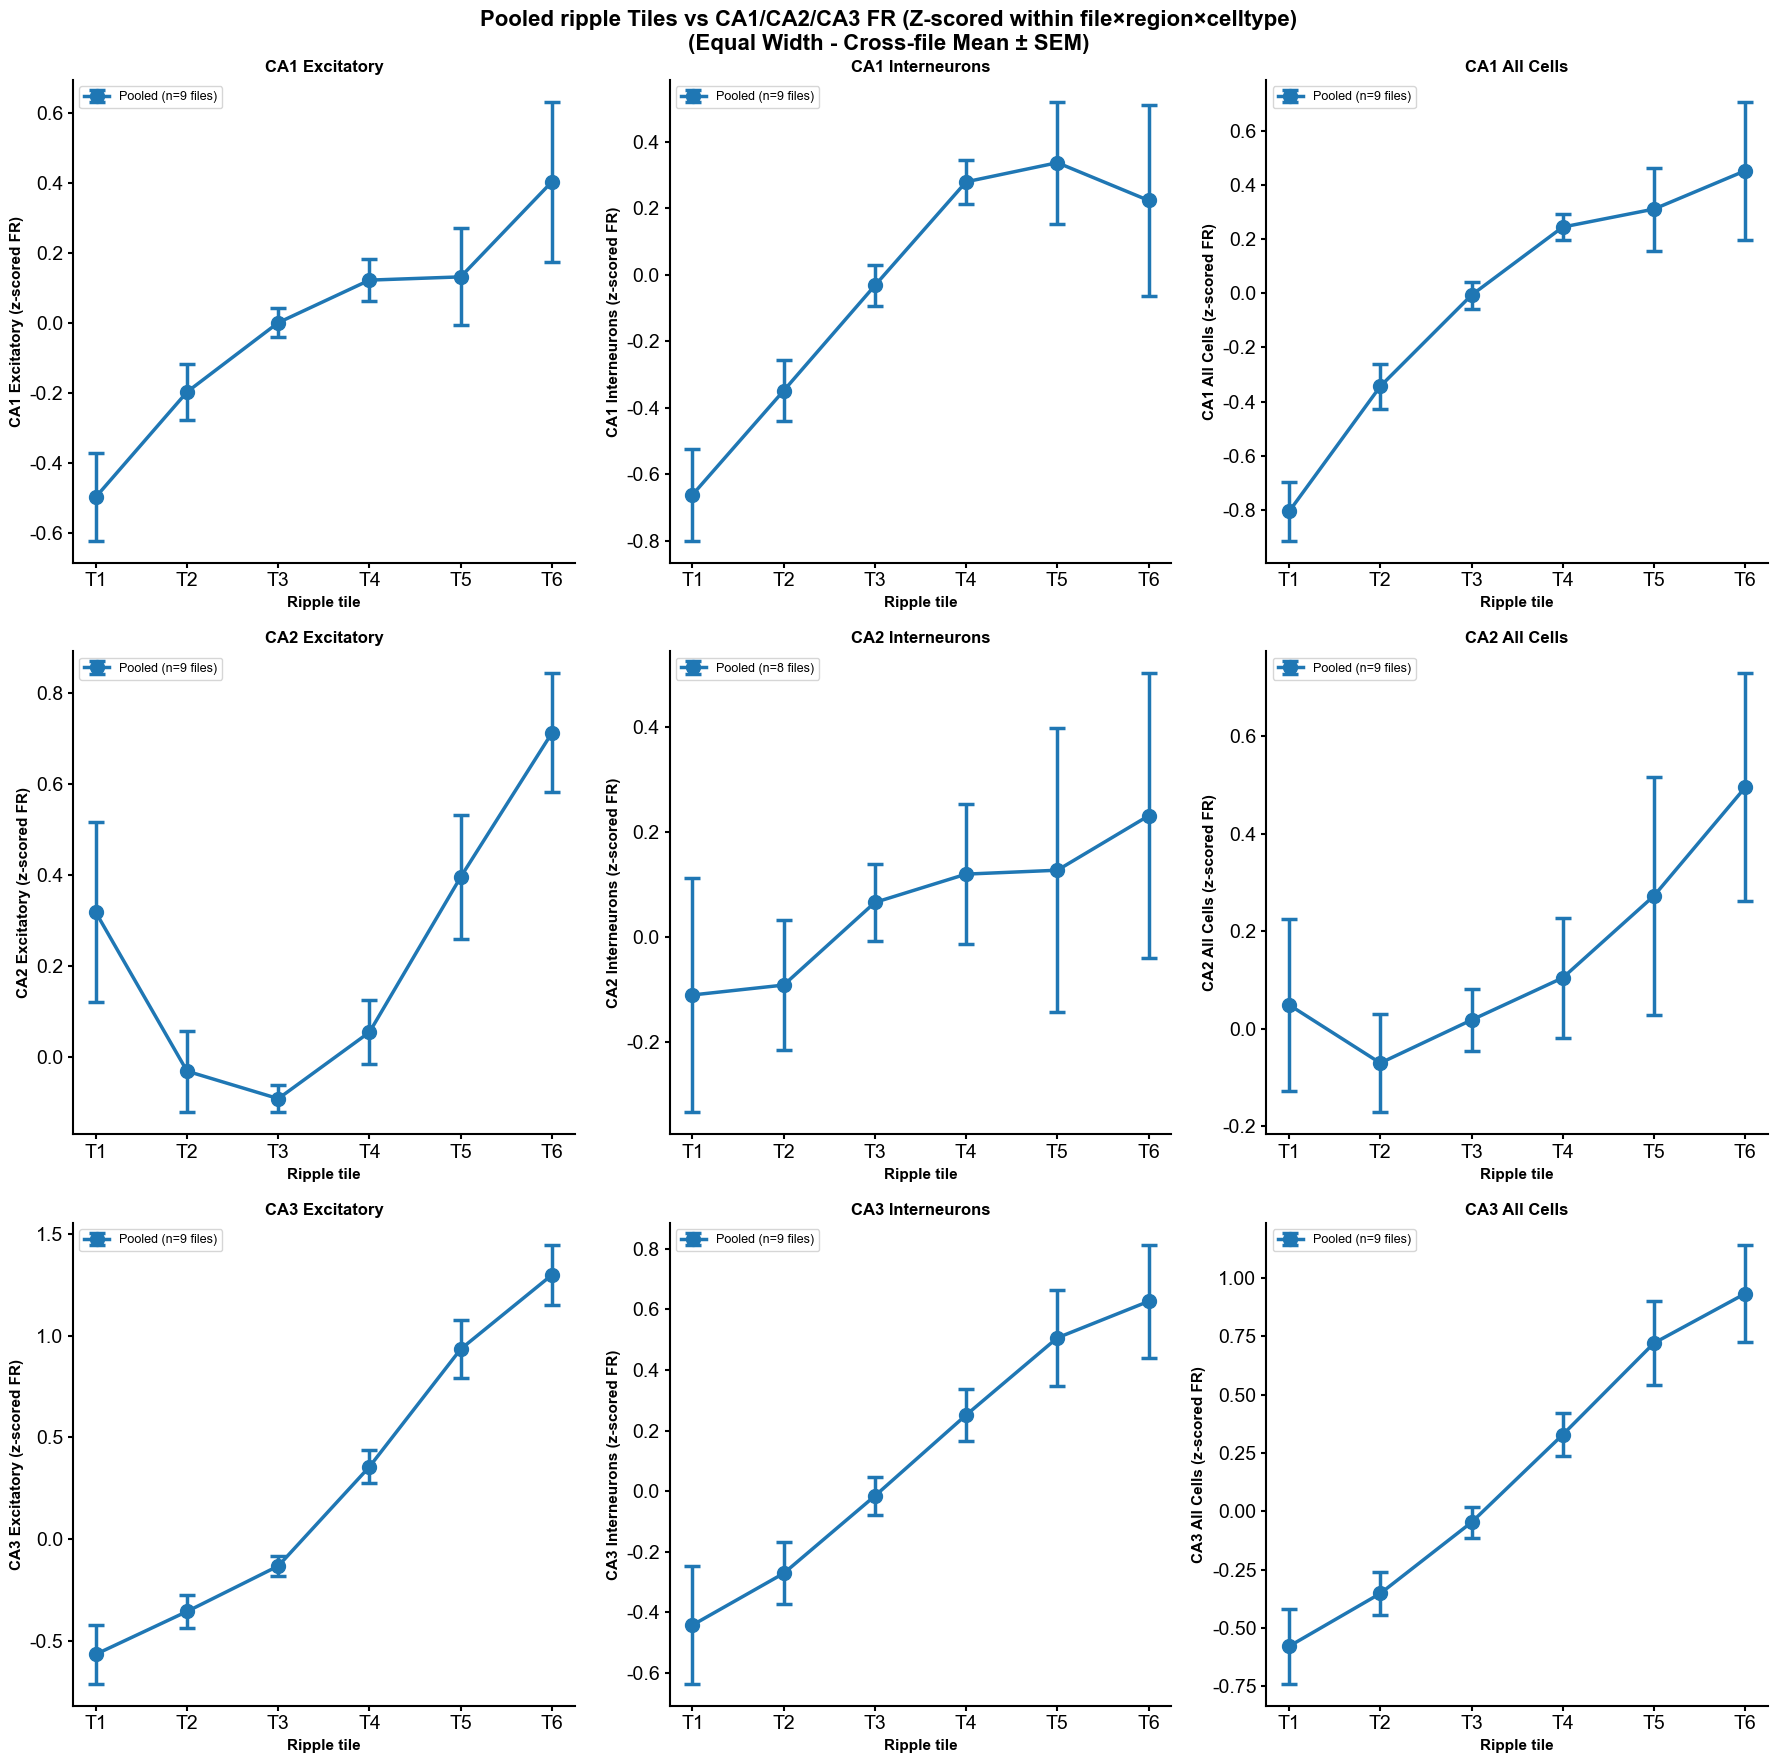


Z-score analysis complete!


In [2]:
import pickle
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from glob import glob

# ==========================================
# CONFIGURATION
# ==========================================
save_dir = r"D:\Documents\GitHub\Sleep_criticaltiy\data\rats\barr_CA2_CA3"

BINNING_METHOD = 'equal_width'   # 'equal_count' (forced sextile) or 'equal_width'
n_tiles = 6

fr_columns = [
    'CA1_E_FR_per_unit', 'CA1_I_FR_per_unit', 'CA1_All_FR_per_unit',
    'CA2_E_FR_per_unit', 'CA2_I_FR_per_unit', 'CA2_All_FR_per_unit',
    'CA3_E_FR_per_unit', 'CA3_I_FR_per_unit', 'CA3_All_FR_per_unit'
]

# ==========================================
# LOAD DATA
# ==========================================
pkl_files = glob(os.path.join(save_dir, "*.pkl"))
print(f"Found {len(pkl_files)} pkl files")
print("="*60)

all_dfs = []
for pkl_file in pkl_files:
    with open(pkl_file, 'rb') as f:
        df = pickle.load(f)
    filename = os.path.basename(pkl_file)
    print(f"Loaded: {filename} - Shape: {df.shape}")
    all_dfs.append(df)

print("\n" + "="*60)
print(f"Total files loaded: {len(all_dfs)}")
print("="*60)

# ==========================================
# HELPERS
# ==========================================

def zscore_within_vector(y):
    """Z-score a 1D array; returns NaNs if std=0 or too few points."""
    y = np.asarray(y, float)
    mu = np.nanmean(y)
    sd = np.nanstd(y)
    if not np.isfinite(sd) or sd == 0:
        return np.full_like(y, np.nan, dtype=float)
    return (y - mu) / sd

def compute_binned_stats_zscore(df, fr_column, n_tiles=6, method='equal_width'):
    """
    For ONE FILE and ONE fr_column:
      1) keep ripple_rate > 0
      2) drop NaNs in x and y
      3) z-score y within this file+region+celltype (i.e., within this column)
      4) compute sextile (equal_count) OR equal_width bins on x
      5) return per-tile means of x and z(y)
    """
    if ('ripple_rate' not in df.columns) or (fr_column not in df.columns):
        return None

    df_filtered = df[(df["state"] == "NREM")].copy()
    if len(df_filtered) == 0:
        return None

    x = df_filtered['ripple_rate'].to_numpy(dtype=float)
    y = df_filtered[fr_column].to_numpy(dtype=float)

    mask = ~(np.isnan(x) | np.isnan(y))
    x_clean = x[mask]
    y_clean = y[mask]
    if len(x_clean) < 3:
        return None

    # --- z-score y within this file+region+celltype (i.e., within this column) ---
    y_z = zscore_within_vector(y_clean)
    # If zscore failed (std==0), bail
    if np.all(np.isnan(y_z)):
        return None

    # --- bin edges from x_clean ---
    if method == 'equal_count':
        # force sextiles by percentiles
        percentiles = np.linspace(0, 100, n_tiles + 1)
        tile_edges = np.percentile(x_clean, percentiles)

        # Important: if barrage_rate has many ties, percentiles can repeat -> empty bins.
        # We'll still handle via NaNs/0 counts below.
    elif method == 'equal_width':
        tile_edges = np.linspace(np.min(x_clean), np.max(x_clean), n_tiles + 1)
    else:
        raise ValueError(f"Unknown method: {method}")

    tile_means_x = []
    tile_means_yz = []
    tile_counts = []

    for i in range(n_tiles):
        if i == n_tiles - 1:
            mask_tile = (x_clean >= tile_edges[i]) & (x_clean <= tile_edges[i+1])
        else:
            mask_tile = (x_clean >= tile_edges[i]) & (x_clean < tile_edges[i+1])

        count = int(np.sum(mask_tile))
        tile_counts.append(count)

        if count > 0:
            tile_means_x.append(np.mean(x_clean[mask_tile]))
            tile_means_yz.append(np.mean(y_z[mask_tile]))
        else:
            tile_means_x.append(np.nan)
            tile_means_yz.append(np.nan)

    return {
        "tile_means_x": np.array(tile_means_x, float),
        "tile_means_y": np.array(tile_means_yz, float),  # <-- z-scored means
        "tile_counts": np.array(tile_counts, int),
        "n_points": int(len(x_clean))
    }

# ==========================================
# COMPUTE PER-FILE STATS THEN POOL
# ==========================================
print("\n" + "="*60)
print(f"Computing Z-scored statistics using method: {BINNING_METHOD.upper()}...")
print("="*60)

pooled_data = {col: [] for col in fr_columns}

for idx, df in enumerate(all_dfs):
    filename = os.path.basename(pkl_files[idx])
    print(f"\nProcessing: {filename}")

    for col in fr_columns:
        stats = compute_binned_stats_zscore(df, col, n_tiles=n_tiles, method=BINNING_METHOD)
        if stats is not None:
            pooled_data[col].append(stats)
            print(f"  {col}: {stats['n_points']} points, tile counts: {stats['tile_counts']}")
        else:
            print(f"  {col}: skipped (missing/empty/zero-std)")

print("\n" + "="*60)
print("Computing pooled statistics (mean ± SEM across files per tile)...")
print("="*60)

pooled_stats = {}

for col in fr_columns:
    if len(pooled_data[col]) == 0:
        print(f"{col}: No data")
        continue

    all_tile_means_x = np.array([s["tile_means_x"] for s in pooled_data[col]], float)  # files x tiles
    all_tile_means_y = np.array([s["tile_means_y"] for s in pooled_data[col]], float)  # files x tiles (z)

    pooled_mean_x = np.nanmean(all_tile_means_x, axis=0)
    pooled_mean_y = np.nanmean(all_tile_means_y, axis=0)

    n_valid = np.sum(~np.isnan(all_tile_means_y), axis=0)
    pooled_std = np.nanstd(all_tile_means_y, axis=0)

    with np.errstate(divide='ignore', invalid='ignore'):
        pooled_sem = pooled_std / np.sqrt(n_valid)

    pooled_stats[col] = {
        "mean_x": pooled_mean_x,
        "mean_y": pooled_mean_y,
        "sem_y": pooled_sem,
        "n_files": len(pooled_data[col]),
        "n_valid": n_valid
    }
    print(f"{col}: pooled from {len(pooled_data[col])} files")

# ==========================================
# PLOTTING (Z-SCORED FR)
# ==========================================
# ==========================================
print("\n" + "="*60)
print("Creating pooled plots (z-scored FR, x = tile)...")
print("="*60)

fig, axes = plt.subplots(3, 3, figsize=(18, 18))
method_title = "Equal Width" if BINNING_METHOD == 'equal_width' else "Forced Sextile (Equal Count)"
fig.suptitle(
    f'Pooled ripple Tiles vs CA1/CA2/CA3 FR (Z-scored within file×region×celltype)\n'
    f'({method_title} - Cross-file Mean ± SEM)',
    fontsize=16, fontweight='bold'
)

plot_configs = [
    ('CA1_E_FR_per_unit', 'CA1 Excitatory', 0, 0),
    ('CA1_I_FR_per_unit', 'CA1 Interneurons', 0, 1),
    ('CA1_All_FR_per_unit', 'CA1 All Cells', 0, 2),
    ('CA2_E_FR_per_unit', 'CA2 Excitatory', 1, 0),
    ('CA2_I_FR_per_unit', 'CA2 Interneurons', 1, 1),
    ('CA2_All_FR_per_unit', 'CA2 All Cells', 1, 2),
    ('CA3_E_FR_per_unit', 'CA3 Excitatory', 2, 0),
    ('CA3_I_FR_per_unit', 'CA3 Interneurons', 2, 1),
    ('CA3_All_FR_per_unit', 'CA3 All Cells', 2, 2),
]

tile_ids = np.arange(1, n_tiles + 1)

for col_name, title, r, c in plot_configs:
    ax = axes[r, c]

    if col_name not in pooled_stats:
        ax.text(0.5, 0.5, 'No data', ha='center', va='center', transform=ax.transAxes)
        ax.set_title(title)
        continue

    st = pooled_stats[col_name]

    # valid tiles are those with a pooled mean (and sem) defined
    valid = np.isfinite(st["mean_y"])  # sem can be nan if n_valid==0; mean_y is the key
    x_plot = tile_ids[valid]
    y_plot = st["mean_y"][valid]
    sem_plot = st["sem_y"][valid]

    if len(x_plot) == 0:
        ax.text(0.5, 0.5, 'No valid tiles', ha='center', va='center', transform=ax.transAxes)
        ax.set_title(title)
        continue

    ax.errorbar(
        x_plot, y_plot, yerr=sem_plot,
        fmt='o-', linewidth=2.5, markersize=10,
        capsize=6, capthick=2.5,
        label=f'Pooled (n={st["n_files"]} files)'
    )

    ax.set_xlabel('Ripple tile', fontsize=11, fontweight='bold')
    ax.set_ylabel(f'{title} (z-scored FR)', fontsize=11, fontweight='bold')
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.legend(fontsize=9, loc='best')

    # nice tile tick labels
    ax.set_xticks(tile_ids)
    ax.set_xticklabels([f"T{i}" for i in tile_ids])

    ax.grid(False)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

print("\n" + "="*60)
print("Z-score analysis complete!")
print("="*60)


C:\Users\Cornell\AppData\Local\Temp\ipykernel_50008\177296275.py:75: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


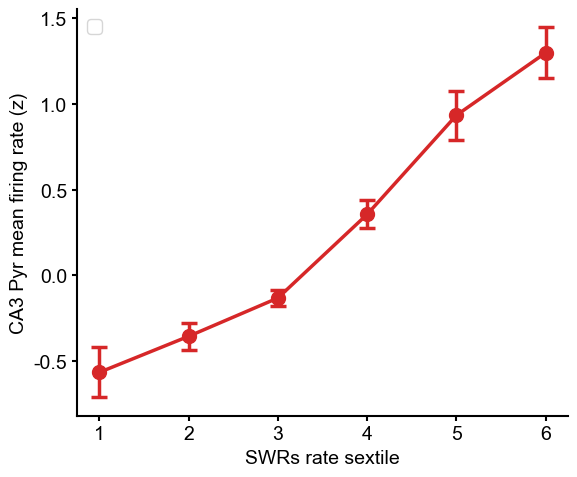

Weighted slope = 0.396 ± 0.049 (SE), t=8.06, p=0.00129, n=6
Pearson r = 0.985, p = 0.000349, n = 6


Text(0.5, 1.0, 'CA3 Excitatory (Pearson r=0.98, p=0.00035)')

In [6]:
import matplotlib as mpl
import scipy.stats as spstats

# Global font: prefer Arial, with safe fallbacks
mpl.rcParams['svg.fonttype'] = 'none' 
mpl.rcParams['text.usetex'] = False
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = [
    'Helvetica Neue', 'Helvetica', 'Arial', 'Liberation Sans', 'DejaVu Sans'
]

# Mathtext to match (works if those faces exist on your system)
mpl.rcParams['mathtext.fontset'] = 'custom'
mpl.rcParams['mathtext.rm'] = 'Helvetica Neue'   # or 'Helvetica'
mpl.rcParams['mathtext.it'] = 'Helvetica Neue:italic'
mpl.rcParams['mathtext.bf'] = 'Helvetica Neue:bold'

# (optional) sizes + minus sign
mpl.rcParams['font.size'] = 16
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams['axes.unicode_minus'] = False

# Global sizes (tweak to taste)
mpl.rcParams['font.size'] = 14
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams["axes.linewidth"] = 1.5       # spine width
mpl.rcParams["xtick.major.width"] =1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5
mpl.rcParams["axes.linewidth"] = 1.5       # spine width
mpl.rcParams["xtick.major.width"] =1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5

col_name = "CA3_E_FR_per_unit"
title = "CA3 Excitatory"

fig, ax = plt.subplots(figsize=(6, 5))

st = pooled_stats[col_name]

tile_ids = np.arange(1, n_tiles + 1)
valid = np.isfinite(st["mean_y"])

x_plot = tile_ids[valid]
y_plot = st["mean_y"][valid]
sem_plot = st["sem_y"][valid]

ax.errorbar(
    x_plot, y_plot, yerr=sem_plot,color="tab:red",
    fmt='o-', linewidth=2.5, markersize=10,
    capsize=6, capthick=2.5,label=None
)

ax.set_xlabel("SWRs rate sextile")
ax.set_ylabel("CA3 Pyr mean firing rate (z)")

ax.set_xticks(tile_ids)
ax.set_xticklabels([f"{i}" for i in tile_ids])

ax.grid(False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend()

plt.tight_layout()
save_path=r"D:\Documents\GitHub\Sleep_criticaltiy\reports\new_plan\supplementary\S3_pooled_CA3_E_FR_per_unit_vs_ripple_tiles.svg"
plt.savefig(save_path, dpi=300)
plt.show()
# weights from SEM (avoid divide-by-zero)
w = 1.0 / np.clip(sem_plot.astype(float), 1e-12, np.inf)**2

# weighted linear fit: y = b0 + b1 x
b1, b0 = np.polyfit(x_plot.astype(float), y_plot.astype(float), deg=1, w=np.sqrt(w))

# get an approximate p-value for slope using weighted regression
# (using effective residual variance)
yhat = b0 + b1 * x_plot
resid = y_plot - yhat
dof = len(x_plot) - 2
s2 = np.sum(w * resid**2) / dof
Sxx = np.sum(w * (x_plot - np.average(x_plot, weights=w))**2)
se_b1 = np.sqrt(s2 / Sxx)
t = b1 / se_b1
p_slope = 2 * spstats.t.sf(np.abs(t), dof)

print(f"Weighted slope = {b1:.3f} ± {se_b1:.3f} (SE), t={t:.2f}, p={p_slope:.3g}, n={len(x_plot)}")
from scipy import stats
import numpy as np

# x_plot, y_plot already defined
r, p = stats.pearsonr(x_plot.astype(float), y_plot.astype(float))
print(f"Pearson r = {r:.3f}, p = {p:.3g}, n = {len(x_plot)}")

# optional: add to title
ax.set_title(f"{title} (Pearson r={r:.2f}, p={p:.2g})")



In [ ]:
"""
Fit ALL FEATURES with robust fallbacks:
1) Try random-slope LMM: yz ~ tile_c + (1 + tile_c | file)
2) If not converged / fails -> random-intercept LMM: yz ~ tile_c + (1 | file)
3) If still fails -> clustered OLS: yz ~ tile_c with SE clustered by file_id

Outputs a summary table across all features, plus a "nonconverged" table.

Assumes you already have:
- save_dir, BINNING_METHOD, n_tiles, MIN_WINDOWS_PER_FILE, fr_columns
- and your PKLs contain 'barrage_rate' + FR columns.
"""

import os
import pickle
import numpy as np
import pandas as pd
from glob import glob

import statsmodels.formula.api as smf
from scipy.stats import norm

# ==========================================
# CONFIGURATION
# ==========================================
save_dir = r"D:\Documents\GitHub\Sleep_criticaltiy\data\rats\barr_CA2_CA3"
BINNING_METHOD = "equal_width"   # "equal_count" or "equal_width"
n_tiles = 6
MIN_WINDOWS_PER_FILE = 10
USE_RANDOM_SLOPE_FIRST = True

fr_columns = [
    'CA1_E_FR_per_unit', 'CA1_I_FR_per_unit', 'CA1_All_FR_per_unit',
    'CA2_E_FR_per_unit', 'CA2_I_FR_per_unit', 'CA2_All_FR_per_unit',
    'CA3_E_FR_per_unit', 'CA3_I_FR_per_unit', 'CA3_All_FR_per_unit'
]

# ==========================================
# HELPERS
# ==========================================
def zscore_within_vector(y):
    y = np.asarray(y, float)
    mu = np.nanmean(y)
    sd = np.nanstd(y)
    if (not np.isfinite(sd)) or (sd == 0):
        return np.full_like(y, np.nan, dtype=float)
    return (y - mu) / sd

def assign_tiles_within_file(x, n_tiles=6, method="equal_width"):
    x = np.asarray(x, float)
    if len(x) == 0:
        return np.array([], dtype=int)

    if method == "equal_count":
        edges = np.percentile(x, np.linspace(0, 100, n_tiles + 1))
    elif method == "equal_width":
        edges = np.linspace(np.min(x), np.max(x), n_tiles + 1)
    else:
        raise ValueError(method)

    tile = np.zeros(len(x), dtype=int)
    for i in range(n_tiles):
        if i == n_tiles - 1:
            m = (x >= edges[i]) & (x <= edges[i+1])
        else:
            m = (x >= edges[i]) & (x < edges[i+1])
        tile[m] = i + 1
    return tile

def make_long_points_for_feature(df, fr_col, file_id, n_tiles=6, method="equal_width"):
    if "ripple_rate" not in df.columns or fr_col not in df.columns:
        return None

    dff = df[df["state"] == "NREM"].copy()
    if len(dff) == 0:
        return None

    x = dff["ripple_rate"].to_numpy(float)
    y = dff[fr_col].to_numpy(float)
    m = ~(np.isnan(x) | np.isnan(y))
    x = x[m]; y = y[m]
    if len(x) < 5:
        return None

    yz = zscore_within_vector(y)
    if np.all(np.isnan(yz)):
        return None

    tile = assign_tiles_within_file(x, n_tiles=n_tiles, method=method)

    out = pd.DataFrame({"file_id": file_id, "tile": tile, "yz": yz})
    out = out[(out["tile"] >= 1) & np.isfinite(out["yz"])].copy()
    return out if len(out) else None

def _wald_p_from_slope_se(slope, se):
    if (not np.isfinite(slope)) or (not np.isfinite(se)) or se == 0:
        return np.nan, np.nan
    z = slope / se
    p = 2 * (1 - norm.cdf(abs(z)))
    return z, p

def fit_rs_lmm(df_long):
    d = df_long.dropna(subset=["yz", "tile", "file_id"]).copy()
    d["tile_c"] = d["tile"] - d["tile"].mean()
    m = smf.mixedlm("yz ~ tile_c", data=d, groups=d["file_id"], re_formula="~tile_c")
    res = m.fit(reml=False, method="lbfgs", maxiter=800)
    slope = res.params.get("tile_c", np.nan)
    se = res.bse.get("tile_c", np.nan)
    z, p = _wald_p_from_slope_se(slope, se)
    return {
        "fit": "RS_LMM",
        "slope_per_tile": slope,
        "se": se,
        "z": z,
        "p": p,
        "converged": bool(getattr(res, "converged", True)),
        "aic": float(res.aic) if hasattr(res, "aic") else np.nan,
        "bic": float(res.bic) if hasattr(res, "bic") else np.nan,
    }

def fit_ri_lmm(df_long):
    d = df_long.dropna(subset=["yz", "tile", "file_id"]).copy()
    d["tile_c"] = d["tile"] - d["tile"].mean()
    m = smf.mixedlm("yz ~ tile_c", data=d, groups=d["file_id"])
    res = m.fit(reml=False, method="lbfgs", maxiter=800)
    slope = res.params.get("tile_c", np.nan)
    se = res.bse.get("tile_c", np.nan)
    z, p = _wald_p_from_slope_se(slope, se)
    return {
        "fit": "RI_LMM",
        "slope_per_tile": slope,
        "se": se,
        "z": z,
        "p": p,
        "converged": bool(getattr(res, "converged", True)),
        "aic": float(res.aic) if hasattr(res, "aic") else np.nan,
        "bic": float(res.bic) if hasattr(res, "bic") else np.nan,
    }

def fit_cluster_ols(df_long):
    d = df_long.dropna(subset=["yz", "tile", "file_id"]).copy()
    d["tile_c"] = d["tile"] - d["tile"].mean()
    ols = smf.ols("yz ~ tile_c", data=d).fit(
        cov_type="cluster", cov_kwds={"groups": d["file_id"]}
    )
    slope = ols.params.get("tile_c", np.nan)
    se = ols.bse.get("tile_c", np.nan)
    p = ols.pvalues.get("tile_c", np.nan)
    z = slope / se if np.isfinite(slope) and np.isfinite(se) and se != 0 else np.nan
    return {
        "fit": "Cluster_OLS",
        "slope_per_tile": slope,
        "se": se,
        "z": z,
        "p": p,
        "converged": True,
        "aic": np.nan,
        "bic": np.nan,
    }

def fit_best_for_feature(df_long, try_random_slope=True):
    # 1) random slope LMM
    if try_random_slope:
        try:
            out = fit_rs_lmm(df_long)
            if out["converged"] and np.isfinite(out["p"]):
                return out
        except Exception as e:
            rs_err = str(e)
        else:
            rs_err = ""
    else:
        rs_err = ""

    # 2) random intercept LMM
    try:
        out = fit_ri_lmm(df_long)
        if out["converged"] and np.isfinite(out["p"]):
            out["note"] = ("RS_LMM failed/not converged: " + rs_err) if rs_err else "Used RI_LMM"
            return out
    except Exception as e:
        ri_err = str(e)

    # 3) clustered OLS fallback
    out = fit_cluster_ols(df_long)
    out["note"] = f"RS_LMM err: {rs_err} | RI_LMM err: {ri_err}"
    return out

# ==========================================
# LOAD ALL FILES
# ==========================================
pkl_files = glob(os.path.join(save_dir, "*.pkl"))
print(f"Found {len(pkl_files)} pkl files")
print("=" * 60)

all_dfs, file_ids = [], []
for p in pkl_files:
    with open(p, "rb") as f:
        df = pickle.load(f)
    fid = os.path.basename(p)
    all_dfs.append(df)
    file_ids.append(fid)
    print(f"Loaded: {fid} - Shape: {df.shape}")
print("=" * 60)

# ==========================================
# BUILD LONG DATA PER FEATURE + FIT
# ==========================================
results = []
sizes = []

for fr_col in fr_columns:
    pieces = []
    for df, fid in zip(all_dfs, file_ids):
        tmp = make_long_points_for_feature(df, fr_col, fid, n_tiles=n_tiles, method=BINNING_METHOD)
        if tmp is None:
            continue
        if len(tmp) >= MIN_WINDOWS_PER_FILE:
            pieces.append(tmp)

    if len(pieces) == 0:
        print(f"{fr_col}: no usable data")
        continue

    df_long = pd.concat(pieces, ignore_index=True)
    out = fit_best_for_feature(df_long, try_random_slope=USE_RANDOM_SLOPE_FIRST)

    out.update({
        "Feature": fr_col,
        "n_windows": int(len(df_long)),
        "n_files": int(df_long["file_id"].nunique()),
        "binning": BINNING_METHOD,
        "n_tiles": n_tiles,
        "sign": "positive" if out["slope_per_tile"] > 0 else "negative",
    })
    results.append(out)

res_df = pd.DataFrame(results).sort_values("p", na_position="last")

print("\n" + "=" * 60)
print("Best-fit results per feature (auto fallback):")
print("=" * 60)
print(res_df[[
    "Feature", "fit", "slope_per_tile", "se", "z", "p",
    "n_windows", "n_files", "sign", "converged"
]])

print("\nNon-converged (if any):")
nonconv = res_df[(res_df["fit"].isin(["RS_LMM","RI_LMM"])) & (res_df["converged"] == False)]
if len(nonconv) == 0:
    print("None")
else:
    print(nonconv[["Feature","fit","slope_per_tile","p","converged","note"]])


Found 9 pkl files
Loaded: AB4_day07.pkl - Shape: (5786, 15)
Loaded: AB4_day08.pkl - Shape: (4407, 15)
Loaded: AB4_day09.pkl - Shape: (8028, 15)
Loaded: AB4_day11.pkl - Shape: (8237, 15)
Loaded: AYA10_day25.pkl - Shape: (5778, 15)
Loaded: AYA10_day27.pkl - Shape: (8177, 15)
Loaded: AYA10_day31.pkl - Shape: (7553, 15)
Loaded: AYA10_day34.pkl - Shape: (5825, 15)
Loaded: AYA7_day25.pkl - Shape: (9610, 14)


c:\Users\Cornell\.conda\envs\criticality\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
c:\Users\Cornell\.conda\envs\criticality\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
c:\Users\Cornell\.conda\envs\criticality\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2206: ConvergenceWarning: MixedLM optimization failed, trying a different optimizer may help.
c:\Users\Cornell\.conda\envs\criticality\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2218: ConvergenceWarning: Gradient optimization failed, |grad| = 27.661919
c:\Users\Cornell\.conda\envs\criticality\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2261: ConvergenceWarning: The Hessian matrix at the estimated parameter values is not positive definite.
c:\Users\Cornell\.conda\envs\criticality\Lib\site


Best-fit results per feature (auto fallback):
               Feature     fit  slope_per_tile        se          z             p  n_windows  n_files      sign  converged
1    CA1_I_FR_per_unit  RI_LMM        0.267190  0.005830  45.830488  0.000000e+00      24621        9  positive       True
2  CA1_All_FR_per_unit  RI_LMM        0.265943  0.005832  45.598509  0.000000e+00      24621        9  positive       True
6    CA3_E_FR_per_unit  RI_LMM        0.416181  0.005464  76.170656  0.000000e+00      24621        9  positive       True
7    CA3_I_FR_per_unit  RI_LMM        0.258200  0.005846  44.164027  0.000000e+00      24621        9  positive       True
8  CA3_All_FR_per_unit  RS_LMM        0.326413  0.064205   5.083949  3.696679e-07      24621        9  positive       True
0    CA1_E_FR_per_unit  RS_LMM        0.144836  0.054545   2.655359  7.922413e-03      24621        9  positive       True
3    CA2_E_FR_per_unit  RS_LMM        0.066984  0.045816   1.462044  1.437291e-01      24621

c:\Users\Cornell\.conda\envs\criticality\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2261: ConvergenceWarning: The Hessian matrix at the estimated parameter values is not positive definite.
